# Assignment 4: Training and Generalization in PyTorch

**Student ID:** 2022320302  
**Name:** 원준서

**Grading (100 points)**

| Item | Topic | Points |
|---|---|---:|
| 1.1 | Evaluation and Gradient Norm | 8 |
| 1.2 | Training Loop with Logging | 10 |
| 1.3 | Visualizing Training Logs | 6 |
| 1.4 | Optimizer Update Rules | 12 |
| 1.5 | Optimizer Comparison | 6 |
| 1.6 | Learning Rate Schedule | 4 |
| 1.7 | Reading Optimization Curves | 6 |
|  | **Part 1 subtotal** | **52** |
| 2.1 | Batch and Layer Normalization | 10 |
| 2.2 | Dropout | 6 |
| 2.3 | Configurable MLP | 4 |
| 2.4 | Normalization and Initialization | 6 |
| 2.5 | Regularization Experiment | 10 |
| 2.6 | Comparing Runs from Saved Logs | 4 |
| 2.7 | Diagnosing Training Curves | 8 |
|  | **Part 2 subtotal** | **48** |
|  | **Total** | **100** |


## Assignment Overview

In this assignment, you will study how neural networks are trained and how
well they generalize, using fully connected networks on CIFAR-10. Instead of
only reading the final accuracy, you will record the **training dynamics** of
every run in a log, save the log to disk, and visualize it to understand what
happened during training. PyTorch autograd computes all backward passes.

- **Part 1 — Optimization and Training Dynamics:** Implement evaluation, a
  training loop that logs per-iteration and per-epoch metrics to CSV files, and
  plots of those logs. Then implement SGD+Momentum, RMSProp, and Adam as
  PyTorch optimizers, compare their training curves, and change the learning
  rate during training with a schedule.
- **Part 2 — Normalization and Generalization:** Implement batch
  normalization, layer normalization, and dropout, build configurable networks,
  study how initialization and normalization interact, and use dropout, weight
  decay, data augmentation, and early stopping to reduce overfitting. Finally,
  reload the saved logs of all runs to compare them.

### Goals

- Log training loss, gradient norm, and learning rate at every iteration, and
  training and validation metrics at every epoch.
- Save training logs to files and visualize them to compare runs.
- Change the learning rate during training and read its effect in the logs.
- Reload saved logs from disk to summarize and compare many runs.
- Implement optimizer update rules on `torch.Tensor` parameters and match the
  `torch.optim` implementations.
- Understand how initialization and normalization affect signal and gradient
  scale in deep networks.
- Implement and apply regularization, and diagnose underfitting, overfitting,
  and optimization failure from training curves.

### References and Conventions

Statements labeled **Lecture Connection** quote the CSAI202 lecture notes
(Lec01–Lec06); each citation names the lecture and the page number of its PDF.
Explanations that go beyond the lecture notes are labeled **Concept
Connection**.

Unless stated otherwise, `N` is batch size, `D` is the feature dimension, `C`
is the number of classes, and `(N, 3, 32, 32)` is a batch of CIFAR-10 images.
Every training run writes its log to `logs/<name>_steps.csv` (one row per
iteration) and `logs/<name>_epochs.csv` (one row per epoch).

Run the notebook from top to bottom. Use a GPU runtime if possible
(`Runtime > Change runtime type`); every experiment also runs on a CPU, only
more slowly. Do not use `torch.optim.SGD` with momentum, `torch.optim.RMSprop`,
`torch.optim.Adam`, `torch.optim.lr_scheduler`, `nn.BatchNorm1d`, `nn.LayerNorm`,
`nn.Dropout`, or `F.dropout` in your implementations; they are used only in the provided
reference checks.


## Colab Setup: Download the CIFAR-10 Dataset

CIFAR-10 contains 60,000 color images of size 32x32 in 10 classes (about
170 MB). `torchvision` shows a progress bar while downloading and skips the
download if the files already exist.


In [1]:
from torchvision.datasets import CIFAR10

CIFAR10('datasets', train=True, download=True)
CIFAR10('datasets', train=False, download=True)


Dataset CIFAR10
    Number of datapoints: 10000
    Root location: datasets
    Split: Test

#### Setup


In [2]:
import csv
import math
import os
import random
from collections import defaultdict

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.datasets import CIFAR10

%matplotlib inline
plt.rcParams['figure.figsize'] = (10.0, 8.0)
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

SEED = 231
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Using device:', device)


def max_relative_error(x, y, eps=1e-8):
    """Return the maximum elementwise relative error between two tensors."""
    x = x.detach().cpu()
    y = y.detach().cpu()
    return ((x - y).abs() / torch.clamp(x.abs() + y.abs(), min=eps)).max().item()


Using device: cuda


#### Provided: CIFAR-10 Data, Mini-Batches, and Training Logs

The following helpers load CIFAR-10 as normalized tensors, iterate over
mini-batches, apply data augmentation, and store training logs. You do not need
to modify them, but read `TrainingLog` carefully: your training loop will use
it.


In [3]:
def load_cifar10(root='datasets', num_val=5000):
    """
    Load CIFAR-10 as float tensors normalized per channel with training
    statistics. The last num_val training images form the validation set.
    """
    def to_tensors(dataset):
        x = torch.from_numpy(dataset.data).permute(0, 3, 1, 2).float().div(255)
        y = torch.tensor(dataset.targets, dtype=torch.long)
        return x, y

    x_train, y_train = to_tensors(CIFAR10(root, train=True, download=True))
    x_test, y_test = to_tensors(CIFAR10(root, train=False, download=True))

    mean = x_train.mean(dim=(0, 2, 3), keepdim=True)
    std = x_train.std(dim=(0, 2, 3), keepdim=True)
    x_train = (x_train - mean) / std
    x_test = (x_test - mean) / std

    num_train = len(x_train) - num_val
    return {
        'x_train': x_train[:num_train], 'y_train': y_train[:num_train],
        'x_val': x_train[num_train:], 'y_val': y_train[num_train:],
        'x_test': x_test, 'y_test': y_test,
    }


class TensorLoader:
    """Iterates over (x, y) mini-batches of tensors that already live on the target device."""

    def __init__(self, x, y, batch_size, shuffle=False, transform=None, seed=SEED):
        self.x, self.y = x, y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.transform = transform
        self.generator = torch.Generator().manual_seed(seed)

    def __len__(self):
        return math.ceil(len(self.x) / self.batch_size)

    def __iter__(self):
        n = len(self.x)
        if self.shuffle:
            order = torch.randperm(n, generator=self.generator)
        else:
            order = torch.arange(n)
        order = order.to(self.x.device)
        for start in range(0, n, self.batch_size):
            index = order[start:start + self.batch_size]
            x, y = self.x[index], self.y[index]
            if self.transform is not None:
                x = self.transform(x)
            yield x, y


def random_flip_and_crop(x, padding=4):
    """Data augmentation: random horizontal flip, then a random crop of the zero-padded image."""
    N, C, H, W = x.shape
    flip = torch.rand(N, device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    padded = F.pad(x, (padding, padding, padding, padding))
    top = torch.randint(0, 2 * padding + 1, (N,), device=x.device)
    left = torch.randint(0, 2 * padding + 1, (N,), device=x.device)
    rows = (top[:, None] + torch.arange(H, device=x.device))[:, None, :, None]
    cols = (left[:, None] + torch.arange(W, device=x.device))[:, None, None, :]
    batch = torch.arange(N, device=x.device)[:, None, None, None]
    channels = torch.arange(C, device=x.device)[None, :, None, None]
    return padded[batch, channels, rows, cols]


class TrainingLog:
    """
    Stores the metrics of one training run.

    - log.steps: dict of lists with one entry per iteration
    - log.epochs: dict of lists with one entry per epoch
    - log.save() writes logs/<name>_steps.csv and logs/<name>_epochs.csv
    - TrainingLog.load(name) reads them back
    """

    def __init__(self, name):
        self.name = name
        self.steps = defaultdict(list)
        self.epochs = defaultdict(list)

    def log_step(self, **values):
        for key, value in values.items():
            self.steps[key].append(float(value))

    def log_epoch(self, **values):
        for key, value in values.items():
            self.epochs[key].append(float(value))

    def save(self, log_dir='logs'):
        os.makedirs(log_dir, exist_ok=True)
        for kind, table in [('steps', self.steps), ('epochs', self.epochs)]:
            with open(os.path.join(log_dir, f'{self.name}_{kind}.csv'), 'w', newline='') as f:
                writer = csv.writer(f)
                writer.writerow(table.keys())
                writer.writerows(zip(*table.values()))

    @classmethod
    def load(cls, name, log_dir='logs'):
        log = cls(name)
        for kind, table in [('steps', log.steps), ('epochs', log.epochs)]:
            with open(os.path.join(log_dir, f'{name}_{kind}.csv'), newline='') as f:
                for row in csv.DictReader(f):
                    for key, value in row.items():
                        table[key].append(float(value))
        return log


In [4]:
# Load CIFAR-10 once and move it to the device. The whole dataset fits in GPU
# memory (about 700 MB), which makes every experiment much faster.
data = {key: value.to(device) for key, value in load_cifar10().items()}
for key, value in data.items():
    print(f'{key}: {tuple(value.shape)}')

# The validation set is shared by every experiment. With 5,000 images, the
# validation accuracy changes little from epoch to epoch because of noise alone.
val_loader = TensorLoader(data['x_val'], data['y_val'], batch_size=500)


def simple_mlp(hidden_dim=256):
    """Provided: a two-layer fully connected network for CIFAR-10 images."""
    return nn.Sequential(
        nn.Flatten(),
        nn.Linear(3 * 32 * 32, hidden_dim),
        nn.ReLU(),
        nn.Linear(hidden_dim, 10),
    )


x_train: (45000, 3, 32, 32)
y_train: (45000,)
x_val: (5000, 3, 32, 32)
y_val: (5000,)
x_test: (10000, 3, 32, 32)
y_test: (10000,)


## Part 1: Optimization and Training Dynamics (52 points)

A final accuracy tells you *where* training ended, but not *how* it got there.
In this part you will build a training loop that records the training dynamics
of every run, save those records as log files, and visualize them. You will
then use the logs to compare optimizers and learning rate schedules.

**Lecture Connection**

> Optimizer updates model parameters  
> Repeated updates improve performance on the training objective  
> *(Lec06 Training and Generalization, p. 6)*

> Optimization failure prevents effective parameter learning  
> *(Lec06 Training and Generalization, p. 32)*


### Section 1: Logging and Visualizing Training


#### Question 1.1: Evaluation and Gradient Norm [code] (8 points)

Implement the two measurements your training loop will record: the loss and
accuracy of a model on a dataset, and the size of the gradient at an update.

**Lecture Connection**

> Training performance measures fit to observed examples  
> Validation performance estimates unseen data behavior  
> Generalization gap compares training and validation performance  
> *(Lec06 Training and Generalization, p. 12)*

> The scale of these derivatives determines whether learning signals remain useful  
> *(Lec02 Feedforward Neural Networks, p. 39)*

**Concept Connection**

The **gradient norm** $\lVert \nabla_\theta \mathcal{L} \rVert_2 =
\sqrt{\sum_i \lVert \nabla_{\theta_i} \mathcal{L} \rVert_2^2}$ measures
how large the learning signal is at an iteration. Tracking it reveals vanishing
gradients (norms near zero) and unstable updates (norms that jump or explode).

**Implementation Guide and Point Breakdown**

- **`evaluate` (5 points):** Call `model.eval()` so that layers such as dropout
  and batch normalization use their evaluation behavior. Sum the per-example
  losses with `F.cross_entropy(..., reduction='sum')`, count correct
  predictions with `argmax(dim=1)`, and divide both by the number of examples.
  The function is decorated with `@torch.no_grad()`.
- **`grad_norm` (3 points):** Accumulate the squared sum of every
  `p.grad` and return its square root as a Python float.

| Tensor | Shape |
|---|---|
| mini-batch `x` | `(N, 3, 32, 32)` |
| labels `y` | `(N,)` |
| `logits` | `(N, 10)` |
| return values | Python floats |

**Expected Check:** Both values match a direct computation on a toy problem
whose last mini-batch is smaller than the others, and `evaluate` leaves the
model in evaluation mode.


In [5]:
@torch.no_grad()
def evaluate(model, loader):
    """
    Inputs:
    - model: classification network
    - loader: iterable of (x, y) mini-batches

    Returns:
    - mean_loss: average cross-entropy over all examples (Python float)
    - accuracy: fraction of correctly classified examples (Python float)
    """
    ############################################################################
    # TODO 1.1 (5/8 points): Put the model in evaluation mode and compute the  #
    # mean cross-entropy and the accuracy over every example in loader. Weight #
    # each mini-batch by its size, since the last batch may be smaller.        #
    ############################################################################
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    for x, y in loader:
        logits = model(x)
        total_loss += F.cross_entropy(logits, y, reduction='sum').item()
        correct += (logits.argmax(dim=1) == y).sum().item()
        count += y.shape[0]
    mean_loss = total_loss / count
    accuracy = correct / count
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return mean_loss, accuracy


def grad_norm(parameters):
    """
    Inputs:
    - parameters: iterable of parameters, e.g. model.parameters()

    Returns:
    - total_norm: L2 norm of all gradients together (Python float)
    """
    ############################################################################
    # TODO 1.1 (3/8 points): Compute the L2 norm of all gradients together, as #
    # if every p.grad were flattened into one long vector. Skip parameters     #
    # whose grad is None.                                                      #
    ############################################################################
    squared_sum = 0.0
    for p in parameters:
        if p.grad is not None:
            squared_sum += p.grad.detach().pow(2).sum().item()
    total_norm = math.sqrt(squared_sum)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return total_norm


In [6]:
# Provided check: evaluate and grad_norm on a toy problem with known answers.
torch.manual_seed(SEED)
toy_x = torch.randn(10, 4)
toy_y = torch.randint(0, 3, (10,))
toy_model = nn.Linear(4, 3)
toy_loader = TensorLoader(toy_x, toy_y, batch_size=4)  # batches of 4, 4, and 2

loss, acc = evaluate(toy_model, toy_loader)
with torch.no_grad():
    toy_logits = toy_model(toy_x)
expected_loss = F.cross_entropy(toy_logits, toy_y).item()
expected_acc = (toy_logits.argmax(dim=1) == toy_y).sum().item() / len(toy_y)
print('loss:', loss, 'expected:', expected_loss)
print('accuracy:', acc, 'expected:', expected_acc)
assert abs(loss - expected_loss) < 1e-6
assert abs(acc - expected_acc) < 1e-9
assert not toy_model.training, 'evaluate should put the model in evaluation mode'

F.cross_entropy(toy_model(toy_x), toy_y).backward()
norm = grad_norm(toy_model.parameters())
expected_norm = nn.utils.clip_grad_norm_(toy_model.parameters(), float('inf')).item()
print('grad norm:', norm, 'expected:', expected_norm)
assert abs(norm - expected_norm) < 1e-5


loss: 1.129100465774536 expected: 1.1291004419326782
accuracy: 0.4 expected: 0.4
grad norm: 0.621631566401514 expected: 0.6216315031051636


#### Question 1.2: Training Loop with Logging [code] (10 points)

Complete a training loop that records the training dynamics of a run in a
`TrainingLog` and saves it to `logs/`.

**Lecture Connection**

> PyTorch accumulates gradients unless they are cleared  
> Therefore a standard iteration includes: Clear previous gradients → Compute predictions → Compute loss → Compute new gradients → Update parameters  
> *(Lec01 Foundations of Deep Learning, p. 52)*

> Input labels shapes gradients and parameter updates should be verified  
> A tiny dataset should be intentionally overfit before full training  
> *(Lec06 Training and Generalization, p. 31)*

> Record model and training configurations  
> Save best checkpoints and evaluation outputs  
> Report enough information to reconstruct the experiment  
> *(Lec06 Training and Generalization, p. 37)*

**Concept Connection**

The log has two granularities. **Per-iteration** rows show the optimization
process itself: how noisy the mini-batch loss is and how the gradient norm
evolves. **Per-epoch** rows compare training and validation performance, which
is what tells you whether the model generalizes. Training performance is
measured with `evaluate` on a fixed set of training examples
(`train_eval_loader`), so that it is directly comparable with the validation
performance.

**Implementation Guide and Point Breakdown**

- **Iteration (6 points):** Clear the gradients, compute the logits and
  `F.cross_entropy`, call `backward()`, measure `grad_norm`, call
  `optimizer.step()`, and log `step`, `loss`, `grad_norm`, and `lr`
  (`optimizer.param_groups[0]['lr']`). Keep `loss` as a tensor; log
  `loss.item()`.
- **Epoch (4 points):** Evaluate on `train_eval_loader` and `val_loader` and
  log `epoch`, `train_loss`, `train_acc`, `val_loss`, and `val_acc`.

The provided code stops a run early if the loss stops being finite, prints a
summary line, and saves the log at the end. If a `scheduler` is given, the
provided code calls `scheduler.step()` at the end of every epoch, so the
`lr` column of the log records how the learning rate changes (Question 1.6).

| Logged per | Keys |
|---|---|
| iteration | `step`, `loss`, `grad_norm`, `lr` |
| epoch | `epoch`, `train_loss`, `train_acc`, `val_loss`, `val_acc` |

**Expected Check:** Training on 100 examples reaches a training accuracy of at
least `0.95`, and the saved CSV files contain exactly the keys above with one
row per iteration and one row per epoch.


In [7]:
def train_model(model, optimizer, train_loader, val_loader, num_epochs, name,
                train_eval_loader=None, scheduler=None, log_dir='logs', verbose=True):
    """
    Train model and record its training dynamics.

    Inputs:
    - model, optimizer: the network and the optimizer that updates its parameters
    - train_loader: mini-batches used for parameter updates
    - val_loader: held-out mini-batches used only for evaluation
    - num_epochs: number of passes over train_loader
    - name: name of the run; the log is saved as <log_dir>/<name>_*.csv
    - train_eval_loader: fixed training examples used to measure training
      performance at the end of every epoch (defaults to train_loader)
    - scheduler: optional learning rate schedule; its step() is called at the
      end of every epoch

    Returns:
    - log: TrainingLog of the run
    """
    if train_eval_loader is None:
        train_eval_loader = train_loader
    log = TrainingLog(name)
    step = 0

    for epoch in range(1, num_epochs + 1):
        model.train()
        for x, y in train_loader:
            ####################################################################
            # TODO 1.2 (6/10 points): Perform one optimizer update on (x, y)   #
            # and store the scalar loss tensor in `loss`. Measure the gradient #
            # norm after backward() and before step(), then log one row with   #
            # log.log_step using the keys step, loss, grad_norm, and lr.       #
            ####################################################################
            optimizer.zero_grad()
            logits = model(x)
            loss = F.cross_entropy(logits, y)
            loss.backward()
            norm = grad_norm(model.parameters())
            optimizer.step()
            log.log_step(step=step, loss=loss.item(), grad_norm=norm,
                         lr=optimizer.param_groups[0]['lr'])
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
            step += 1
            if not math.isfinite(loss.item()):
                break

        ########################################################################
        # TODO 1.2 (4/10 points): Evaluate the model on train_eval_loader and  #
        # val_loader, then log one row with log.log_epoch using the keys       #
        # epoch, train_loss, train_acc, val_loss, and val_acc.                 #
        ########################################################################
        train_loss, train_acc = evaluate(model, train_eval_loader)
        val_loss, val_acc = evaluate(model, val_loader)
        log.log_epoch(epoch=epoch, train_loss=train_loss, train_acc=train_acc,
                      val_loss=val_loss, val_acc=val_acc)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################

        if scheduler is not None:
            scheduler.step()

        if verbose:
            print(f"[{name}] epoch {epoch:3d}/{num_epochs}: "
                  f"train loss {log.epochs['train_loss'][-1]:.4f}, "
                  f"train acc {log.epochs['train_acc'][-1]:.3f}, "
                  f"val loss {log.epochs['val_loss'][-1]:.4f}, "
                  f"val acc {log.epochs['val_acc'][-1]:.3f}")
        if not math.isfinite(loss.item()):
            print(f'[{name}] the loss is not finite; stopping early.')
            break

    log.save(log_dir)
    return log


In [8]:
# Provided check: overfit 100 training examples and confirm that the log was saved.
small_loader = TensorLoader(data['x_train'][:100], data['y_train'][:100],
                            batch_size=25, shuffle=True)

torch.manual_seed(SEED)
model = simple_mlp().to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
sanity_log = train_model(model, optimizer, small_loader, val_loader,
                         num_epochs=20, name='sanity_overfit')

reloaded = TrainingLog.load('sanity_overfit')
assert set(reloaded.steps) == {'step', 'loss', 'grad_norm', 'lr'}, set(reloaded.steps)
assert set(reloaded.epochs) == {'epoch', 'train_loss', 'train_acc', 'val_loss', 'val_acc'}, set(reloaded.epochs)
assert len(reloaded.steps['loss']) == 20 * len(small_loader)
assert reloaded.epochs['epoch'] == [float(e) for e in range(1, 21)]
print('final training accuracy:', reloaded.epochs['train_acc'][-1])
assert reloaded.epochs['train_acc'][-1] >= 0.95
print('The log was saved to logs/sanity_overfit_steps.csv and logs/sanity_overfit_epochs.csv')


[sanity_overfit] epoch   1/20: train loss 1.2553, train acc 0.580, val loss 2.8572, val acc 0.175
[sanity_overfit] epoch   2/20: train loss 0.6320, train acc 0.900, val loss 2.6949, val acc 0.197
[sanity_overfit] epoch   3/20: train loss 0.3305, train acc 0.930, val loss 3.1015, val acc 0.174
[sanity_overfit] epoch   4/20: train loss 0.2041, train acc 0.960, val loss 3.6859, val acc 0.180
[sanity_overfit] epoch   5/20: train loss 0.0750, train acc 1.000, val loss 3.6366, val acc 0.192
[sanity_overfit] epoch   6/20: train loss 0.0536, train acc 1.000, val loss 3.6905, val acc 0.195
[sanity_overfit] epoch   7/20: train loss 0.0345, train acc 1.000, val loss 3.8626, val acc 0.198
[sanity_overfit] epoch   8/20: train loss 0.0214, train acc 1.000, val loss 4.0561, val acc 0.197
[sanity_overfit] epoch   9/20: train loss 0.0138, train acc 1.000, val loss 4.2183, val acc 0.196
[sanity_overfit] epoch  10/20: train loss 0.0101, train acc 1.000, val loss 4.3486, val acc 0.194
[sanity_overfit] epo

[sanity_overfit] epoch  19/20: train loss 0.0032, train acc 1.000, val loss 4.6065, val acc 0.199
[sanity_overfit] epoch  20/20: train loss 0.0031, train acc 1.000, val loss 4.6207, val acc 0.200
final training accuracy: 1.0
The log was saved to logs/sanity_overfit_steps.csv and logs/sanity_overfit_epochs.csv


#### Question 1.3: Visualizing Training Logs [code] (6 points)

Write a plotting function that shows the training dynamics of one or more runs
side by side, so that runs can be compared at a glance.

**Lecture Connection**

> Training loss shows optimization progress  
> Validation loss shows generalization behavior  
> Training validation gaps reveal possible overfitting  
> Plateaus reveal limited progress  
> Strong oscillation suggests unstable optimization  
> *(Lec06 Training and Generalization, p. 28)*

**Concept Connection**

The mini-batch loss is noisy because every iteration sees different examples.
A **moving average** over the last few iterations reveals the trend without
hiding sudden changes. Gradient norms can span several orders of magnitude, so
they are easier to read on a logarithmic axis. Plotting the **learning rate**
next to them shows when the update size changed, and the **generalization
gap** (training accuracy minus validation accuracy) shows how far training
and validation performance drift apart from epoch to epoch.

**Implementation Guide and Point Breakdown**

- **`moving_average` (2 points):** Use a trailing window; the first entries
  average over fewer values. `np.cumsum` gives a loop-free solution.
- **`plot_logs` (4 points):** Fill the provided 2 x 3 grid of axes:

| Axis | x-axis | Curves for each run |
|---|---|---|
| `axes[0, 0]` | iteration | smoothed training loss |
| `axes[0, 1]` | iteration | gradient norm (log scale) |
| `axes[0, 2]` | iteration | learning rate (log scale) |
| `axes[1, 0]` | epoch | training loss (solid), validation loss (dashed) |
| `axes[1, 1]` | epoch | training accuracy (solid), validation accuracy (dashed) |
| `axes[1, 2]` | epoch | generalization gap (training accuracy − validation accuracy) |

**Expected Check:** The moving average matches small hand-computed examples,
and plotting two runs produces 2, 2, 2, 4, 4, and 2 lines on the six axes with
log-scale gradient-norm and learning-rate axes.


In [9]:
def moving_average(values, window):
    """
    Inputs:
    - values: sequence of numbers
    - window: number of most recent values to average

    Returns:
    - smoothed: NumPy array with the same length as values
    """
    ############################################################################
    # TODO 1.3 (2/6 points): Return a NumPy array whose i-th entry is the mean #
    # of values[max(0, i - window + 1) : i + 1].                               #
    ############################################################################
    values = np.asarray(values, dtype=float)
    cumsum = np.cumsum(values)
    idx = np.arange(len(values))
    start = np.maximum(0, idx - window + 1)
    window_sum = cumsum - np.where(start > 0, cumsum[start - 1], 0.0)
    smoothed = window_sum / (idx - start + 1)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return smoothed


def plot_logs(logs, smooth=20):
    """
    Plot the training dynamics of one or more runs on a 2 x 3 grid:
    (0, 0) smoothed iteration loss, (0, 1) iteration gradient norm (log scale),
    (0, 2) iteration learning rate (log scale),
    (1, 0) train and validation loss per epoch,
    (1, 1) train and validation accuracy per epoch,
    (1, 2) generalization gap (train accuracy - validation accuracy) per epoch.

    Inputs:
    - logs: list of TrainingLog objects
    - smooth: window of the moving average for the iteration loss

    Returns:
    - fig: the matplotlib figure
    """
    fig, axes = plt.subplots(2, 3, figsize=(19, 9))
    ############################################################################
    # TODO 1.3 (4/6 points): Draw every run on the six axes described in the   #
    # docstring. Use color f"C{i}" for the i-th run, solid lines for training  #
    # and dashed lines for validation, log-scale y-axes for the gradient norm  #
    # and the learning rate, and axis labels and a legend on every subplot.    #
    ############################################################################
    for i, log in enumerate(logs):
        color = f"C{i}"
        steps, epochs = log.steps, log.epochs
        gap = np.array(epochs['train_acc']) - np.array(epochs['val_acc'])

        axes[0, 0].plot(steps['step'], moving_average(steps['loss'], smooth), color=color, label=log.name)
        axes[0, 1].plot(steps['step'], steps['grad_norm'], color=color, label=log.name)
        axes[0, 2].plot(steps['step'], steps['lr'], color=color, label=log.name)
        axes[1, 0].plot(epochs['epoch'], epochs['train_loss'], color=color, label=f'{log.name} train')
        axes[1, 0].plot(epochs['epoch'], epochs['val_loss'], color=color, linestyle='--', label=f'{log.name} val')
        axes[1, 1].plot(epochs['epoch'], epochs['train_acc'], color=color, label=f'{log.name} train')
        axes[1, 1].plot(epochs['epoch'], epochs['val_acc'], color=color, linestyle='--', label=f'{log.name} val')
        axes[1, 2].plot(epochs['epoch'], gap, color=color, label=log.name)

    axes[0, 1].set_yscale('log')
    axes[0, 2].set_yscale('log')
    titles = [['training loss (smoothed)', 'gradient norm', 'learning rate'],
              ['loss per epoch', 'accuracy per epoch', 'generalization gap']]
    ylabels = [['loss', 'gradient norm', 'learning rate'],
               ['cross-entropy loss', 'accuracy', 'train acc - val acc']]
    for r in range(2):
        for c in range(3):
            ax = axes[r, c]
            ax.set_title(titles[r][c])
            ax.set_xlabel('iteration' if r == 0 else 'epoch')
            ax.set_ylabel(ylabels[r][c])
            ax.legend(fontsize=8)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    fig.tight_layout()
    return fig


lines per axis: [2, 2, 2, 4, 4, 2]


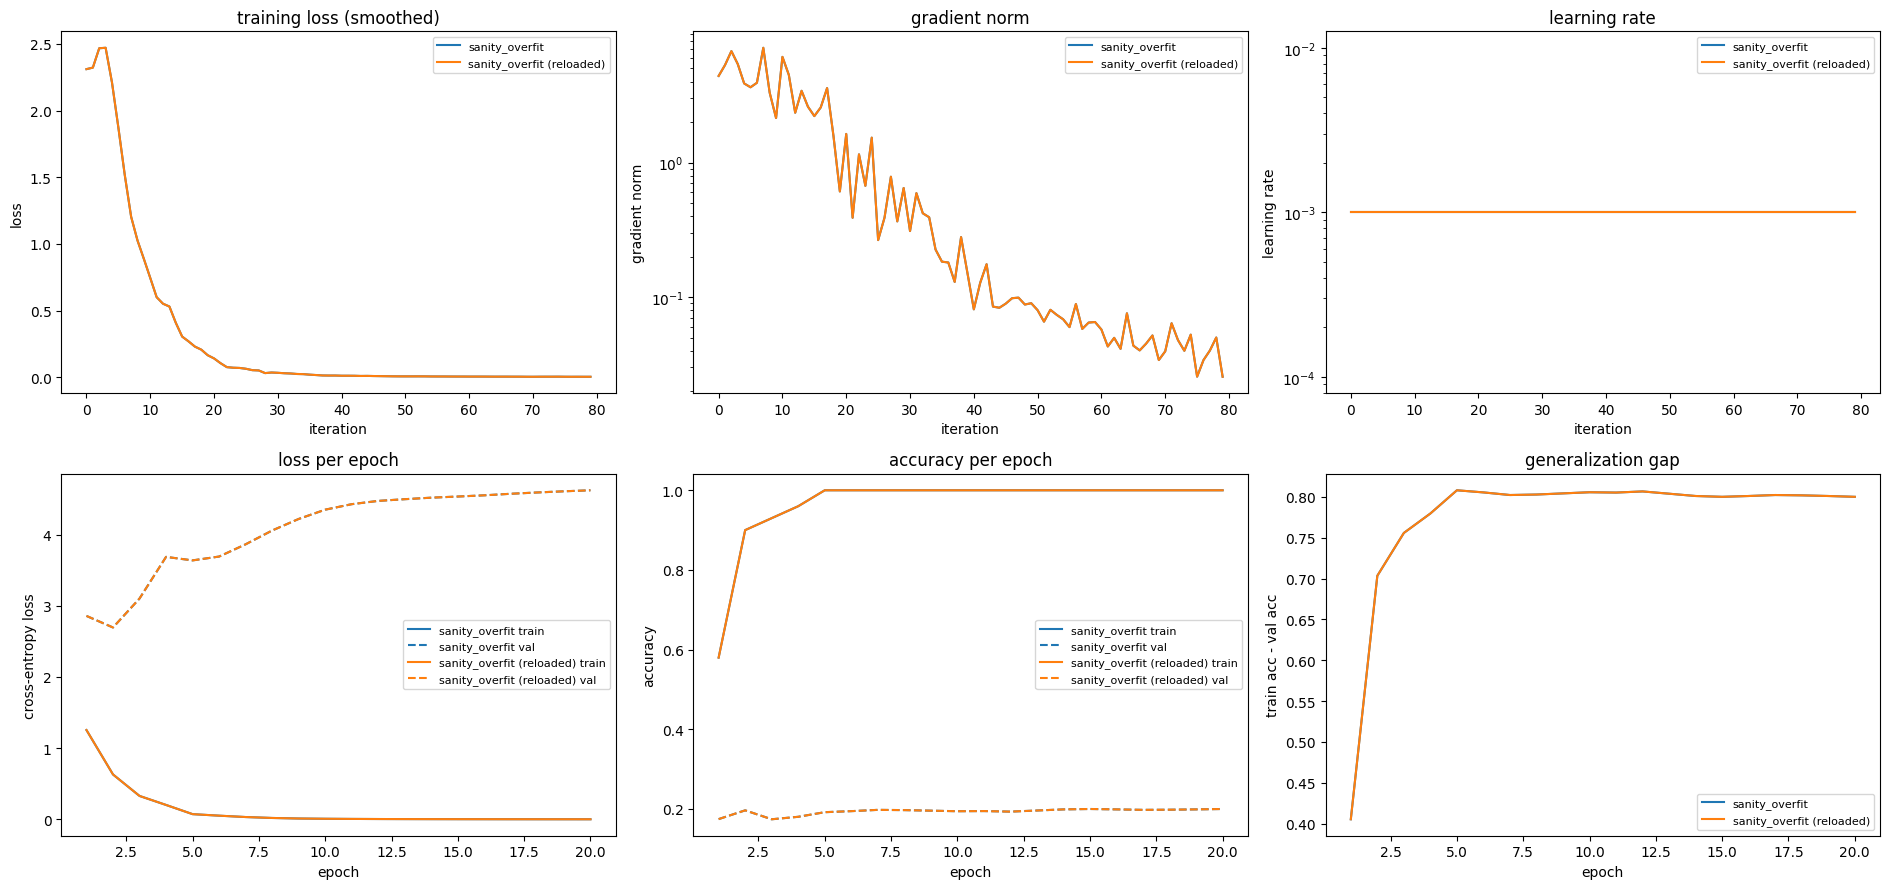

In [10]:
# Provided check: moving average values and the plot layout.
assert np.allclose(moving_average([1, 2, 3, 4], window=2), [1, 1.5, 2.5, 3.5])
assert np.allclose(moving_average([4, 0, 2], window=5), [4, 2, 2])

second_log = TrainingLog.load('sanity_overfit')
second_log.name = 'sanity_overfit (reloaded)'
fig = plot_logs([sanity_log, second_log], smooth=4)
lines_per_axis = [len(ax.get_lines()) for ax in fig.axes]
print('lines per axis:', lines_per_axis)
assert lines_per_axis == [2, 2, 2, 4, 4, 2]
assert fig.axes[1].get_yscale() == 'log'
assert fig.axes[2].get_yscale() == 'log'
plt.show()


### Section 2: Optimizers and Learning Rate Schedules


#### Question 1.4: Optimizer Update Rules [code] (12 points)

Implement three update rules as subclasses of `torch.optim.Optimizer`, so that
they can replace the built-in optimizers in `train_model`.

**Lecture Connection**

> Momentum introduces information from previous updates  
> Build speed in directions with consistent gradients  
> *(Lec01 Foundations of Deep Learning, p. 44)*

> Different parameters can receive differently scaled updates  
> Adam changes how gradients are used  
> It does not replace backpropagation  
> *(Lec01 Foundations of Deep Learning, p. 45)*

**Concept Connection**

For a parameter $w$ with gradient $g$ and learning rate $\eta$, using the same
conventions as `torch.optim`:

$$
\textbf{SGD+Momentum:}\quad v \leftarrow \mu v + g,\qquad w \leftarrow w - \eta v
$$

$$
\textbf{RMSProp:}\quad s \leftarrow \rho s + (1-\rho) g^2,\qquad
w \leftarrow w - \eta \frac{g}{\sqrt{s} + \epsilon}
$$

$$
\textbf{Adam:}\quad t \leftarrow t + 1,\quad
m \leftarrow \beta_1 m + (1-\beta_1) g,\quad
v \leftarrow \beta_2 v + (1-\beta_2) g^2,
$$

$$
\hat m = \frac{m}{1-\beta_1^t},\quad \hat v = \frac{v}{1-\beta_2^t},\qquad
w \leftarrow w - \eta \frac{\hat m}{\sqrt{\hat v} + \epsilon}
$$

The squares, square roots, and divisions are elementwise. The moments start at
zero, so without the bias correction Adam's first updates would be too small.

**Implementation Guide and Point Breakdown**

`step()` already loops over every parameter `p` with a gradient and runs under
`torch.no_grad()`. `self.state[p]` is a dictionary that persists across steps;
use it to store the optimizer's buffers. Update `p` in place (for example with
`p.add_(...)` or `p.addcdiv_(...)`).

- **SGD+Momentum (3 points):** velocity buffer.
- **RMSProp (3 points):** running average of squared gradients.
- **Adam (6 points):** step count, first and second moments, bias correction.

| Tensor | Shape |
|---|---|
| `p`, `p.grad` | any parameter shape |
| every buffer in `self.state[p]` | same shape as `p` |

**Expected Check:** After five steps on a small least-squares problem, each
optimizer matches the corresponding `torch.optim` optimizer with relative error
below `1e-6`.


In [11]:
class SGDMomentum(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, momentum=0.9):
        super().__init__(params, dict(lr=lr, momentum=momentum))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, momentum = group['lr'], group['momentum']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                ################################################################
                # TODO 1.4 (3/12 points): Implement the SGD+Momentum update.   #
                # Keep the velocity in state["velocity"] (initialized to       #
                # zeros) and update p in place.                                #
                ################################################################
                if 'velocity' not in state:
                    state['velocity'] = torch.zeros_like(p)
                velocity = state['velocity']
                velocity.mul_(momentum).add_(p.grad)
                p.add_(velocity, alpha=-lr)
                ################################################################
                #                         END OF YOUR CODE                     #
                ################################################################


class RMSProp(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-2, decay_rate=0.99, eps=1e-8):
        super().__init__(params, dict(lr=lr, decay_rate=decay_rate, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, decay_rate, eps = group['lr'], group['decay_rate'], group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                ################################################################
                # TODO 1.4 (3/12 points): Implement the RMSProp update. Keep   #
                # the running average of squared gradients in                  #
                # state["square_avg"] (initialized to zeros) and update p in   #
                # place.                                                       #
                ################################################################
                if 'square_avg' not in state:
                    state['square_avg'] = torch.zeros_like(p)
                square_avg = state['square_avg']
                square_avg.mul_(decay_rate).addcmul_(p.grad, p.grad, value=1 - decay_rate)
                p.addcdiv_(p.grad, square_avg.sqrt().add_(eps), value=-lr)
                ################################################################
                #                         END OF YOUR CODE                     #
                ################################################################


class Adam(torch.optim.Optimizer):
    def __init__(self, params, lr=1e-3, beta1=0.9, beta2=0.999, eps=1e-8):
        super().__init__(params, dict(lr=lr, beta1=beta1, beta2=beta2, eps=eps))

    @torch.no_grad()
    def step(self):
        for group in self.param_groups:
            lr, beta1, beta2, eps = group['lr'], group['beta1'], group['beta2'], group['eps']
            for p in group['params']:
                if p.grad is None:
                    continue
                state = self.state[p]
                ################################################################
                # TODO 1.4 (6/12 points): Implement the Adam update with bias  #
                # correction. Keep the step count in state["t"] and the        #
                # moments in state["m"] and state["v"] (initialized to zeros), #
                # and update p in place.                                       #
                ################################################################
                if 't' not in state:
                    state['t'] = 0
                    state['m'] = torch.zeros_like(p)
                    state['v'] = torch.zeros_like(p)
                state['t'] += 1
                t, m, v = state['t'], state['m'], state['v']
                m.mul_(beta1).add_(p.grad, alpha=1 - beta1)
                v.mul_(beta2).addcmul_(p.grad, p.grad, value=1 - beta2)
                m_hat = m / (1 - beta1 ** t)
                v_hat = v / (1 - beta2 ** t)
                p.addcdiv_(m_hat, v_hat.sqrt().add_(eps), value=-lr)
                ################################################################
                #                         END OF YOUR CODE                     #
                ################################################################


In [12]:
# Provided check: compare each optimizer with torch.optim on a least-squares problem.
def compare_with_reference(make_ours, make_reference, num_steps=5):
    torch.manual_seed(SEED)
    w0 = torch.randn(4, 3, dtype=torch.float64)
    x = torch.randn(6, 4, dtype=torch.float64)
    target = torch.randn(6, 3, dtype=torch.float64)
    ours = w0.clone().requires_grad_()
    reference = w0.clone().requires_grad_()
    optimizers = [(ours, make_ours([ours])), (reference, make_reference([reference]))]
    for _ in range(num_steps):
        for w, optimizer in optimizers:
            optimizer.zero_grad()
            ((x @ w - target) ** 2).sum().backward()
            optimizer.step()
    assert not torch.equal(ours, w0), 'the parameter was not updated'
    return max_relative_error(ours, reference)


checks = {
    'SGDMomentum': (lambda p: SGDMomentum(p, lr=1e-2, momentum=0.9),
                    lambda p: torch.optim.SGD(p, lr=1e-2, momentum=0.9)),
    'RMSProp': (lambda p: RMSProp(p, lr=1e-2, decay_rate=0.99, eps=1e-8),
                lambda p: torch.optim.RMSprop(p, lr=1e-2, alpha=0.99, eps=1e-8)),
    'Adam': (lambda p: Adam(p, lr=1e-2, beta1=0.9, beta2=0.999, eps=1e-8),
             lambda p: torch.optim.Adam(p, lr=1e-2, betas=(0.9, 0.999), eps=1e-8)),
}
for name, (make_ours, make_reference) in checks.items():
    error = compare_with_reference(make_ours, make_reference)
    print(f'{name} relative error: {error:.2e}')
    assert error < 1e-6


SGDMomentum relative error: 0.00e+00
RMSProp relative error: 0.00e+00
Adam relative error: 8.38e-17


#### Question 1.5: Optimizer Comparison [code] (6 points)

Train the same network with plain SGD and your three optimizers, and compare
their training dynamics with `plot_logs`.

**Lecture Connection**

> The learning rate controls the magnitude of parameter updates.  
> Too large: Updates may overshoot useful regions; Loss may oscillate or diverge  
> *(Lec01 Foundations of Deep Learning, p. 43)*

> Loss may diverge or oscillate strongly  
> Gradients may vanish or explode  
> Learning rate may be inappropriate  
> *(Lec06 Training and Generalization, p. 33)*

**Implementation Guide**

Every run trains `simple_mlp()` from the same initialization on 4,000 training
images for 10 epochs with batch size 100. Choose one learning rate per
optimizer. Each optimizer has its own scale: a learning rate that works for one
can be far too large or too small for another. Try a few values on a
logarithmic grid (for example `1e-4`, `1e-3`, `1e-2`, `1e-1`) and keep the one
that trains fastest without becoming unstable.

The provided cells then rerun Adam with a learning rate ten times larger than
the usual default (`1e-2`), so that you can see what an unstable run looks like
in the logs.

**Expected Check:** Every run reaches a best validation accuracy of at least
`0.35`, and SGD+Momentum, RMSProp, and Adam each end with a lower training
loss than plain SGD.


sgd       lr=0.03: final train loss 1.1054, best val acc 0.420


momentum  lr=0.01: final train loss 0.5587, best val acc 0.421


rmsprop   lr=0.0003: final train loss 0.7374, best val acc 0.422


adam      lr=0.001: final train loss 0.3770, best val acc 0.406


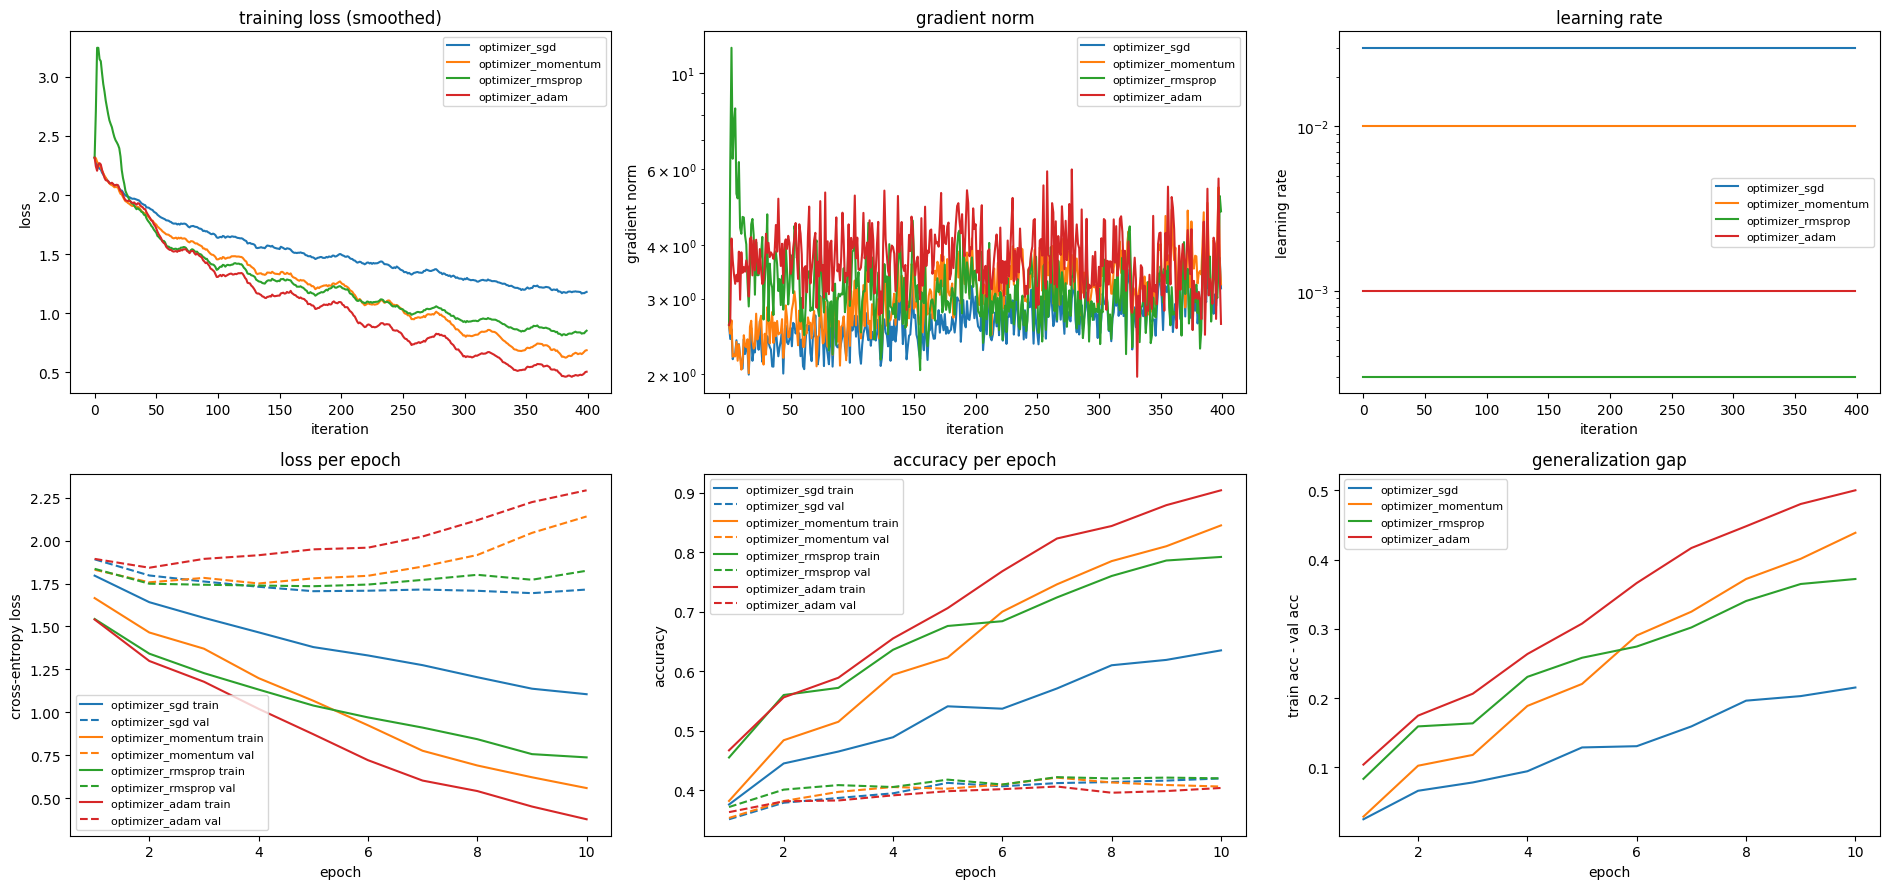

In [13]:
##############################################################################
# TODO 1.5 (6 points): Choose a learning rate for each optimizer so that     #
# every run trains stably and the comparison is fair.                        #
##############################################################################
learning_rates = {
    'sgd': 0.03,
    'momentum': 0.01,
    'rmsprop': 0.0003,
    'adam': 0.001,
}
##############################################################################
#                         END OF YOUR CODE                                   #
##############################################################################

def make_opt_loader():
    # A new loader per run gives every run the same sequence of mini-batches.
    return TensorLoader(data['x_train'][:4000], data['y_train'][:4000],
                        batch_size=100, shuffle=True)


opt_eval_loader = TensorLoader(data['x_train'][:1000], data['y_train'][:1000], batch_size=500)
make_optimizer = {
    'sgd': lambda params, lr: torch.optim.SGD(params, lr=lr),
    'momentum': lambda params, lr: SGDMomentum(params, lr=lr, momentum=0.9),
    'rmsprop': lambda params, lr: RMSProp(params, lr=lr),
    'adam': lambda params, lr: Adam(params, lr=lr),
}

optimizer_logs = {}
for name, lr in learning_rates.items():
    torch.manual_seed(SEED)
    model = simple_mlp().to(device)
    optimizer_logs[name] = train_model(
        model, make_optimizer[name](model.parameters(), lr), make_opt_loader(), val_loader,
        num_epochs=10, name=f'optimizer_{name}', train_eval_loader=opt_eval_loader,
        verbose=False)
    epochs = optimizer_logs[name].epochs
    print(f"{name:9s} lr={lr:g}: final train loss {epochs['train_loss'][-1]:.4f}, "
          f"best val acc {max(epochs['val_acc']):.3f}")

plot_logs(list(optimizer_logs.values()))
plt.show()


In [14]:
# Provided check: every optimizer trains, and the improved methods fit faster than SGD.
final_train_loss = {name: log.epochs['train_loss'][-1] for name, log in optimizer_logs.items()}
best_val_acc = {name: max(log.epochs['val_acc']) for name, log in optimizer_logs.items()}
for name in optimizer_logs:
    assert best_val_acc[name] >= 0.35, f'{name}: best val acc {best_val_acc[name]:.3f}'
for name in ['momentum', 'rmsprop', 'adam']:
    assert final_train_loss[name] < final_train_loss['sgd'], name
print('Optimizer comparison check passed')


Optimizer comparison check passed


adam lr=0.01: final train loss 4.2181, best val acc 0.347


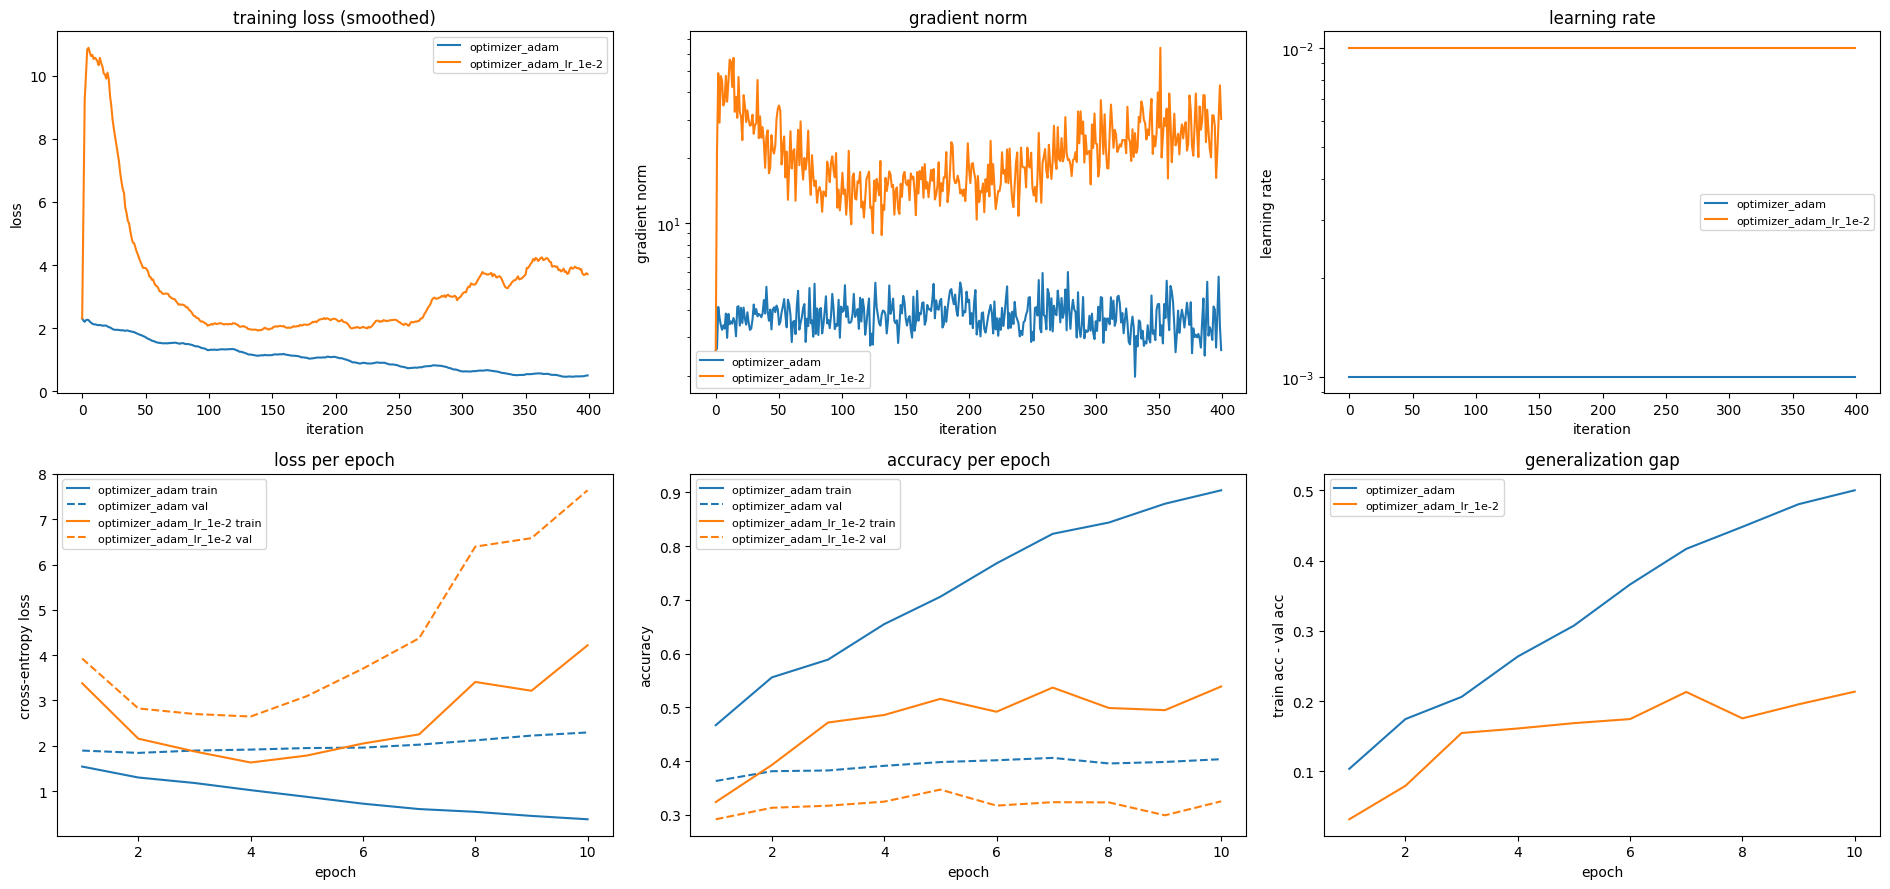

In [15]:
# Provided: the same Adam run with a learning rate that is too large.
torch.manual_seed(SEED)
model = simple_mlp().to(device)
large_lr_log = train_model(
    model, Adam(model.parameters(), lr=1e-2), make_opt_loader(), val_loader,
    num_epochs=10, name='optimizer_adam_lr_1e-2', train_eval_loader=opt_eval_loader,
    verbose=False)
print(f"adam lr=0.01: final train loss {large_lr_log.epochs['train_loss'][-1]:.4f}, "
      f"best val acc {max(large_lr_log.epochs['val_acc']):.3f}")

plot_logs([optimizer_logs['adam'], large_lr_log])
plt.show()


#### Question 1.6: Learning Rate Schedule [code] (4 points)

Implement a step-decay learning rate schedule and use the logs to see how
changing the learning rate during training changes the training dynamics.

**Lecture Connection**

> Larger early updates can accelerate learning
> Smaller later updates can support refinement
> Fixed learning rates may become inefficient
> Epoch based schedules follow training progress
> *(Lec06 Training and Generalization, p. 29)*

**Concept Connection**

A **step-decay** schedule multiplies the learning rate by a factor $\gamma < 1$
after every $s$ epochs. After $e$ completed epochs, the learning rate of a
parameter group whose initial learning rate is $\eta_0$ is

$$
\eta_e = \eta_0 \, \gamma^{\lfloor e / s \rfloor}.
$$

`train_model` calls `scheduler.step()` at the end of every epoch, and every
logged iteration records the current learning rate, so the `lr` panel of
`plot_logs` shows exactly when the update size changed.

**Implementation Guide**

`StepDecay` stores the initial learning rate of every parameter group in
`self.base_lrs` and counts completed epochs in `self.epoch`. Implement `step()`
so that it sets `group['lr']` of every parameter group according to the
equation above. Do not use `torch.optim.lr_scheduler`.

| Quantity | Meaning |
|---|---|
| `self.epoch` | number of completed epochs (incremented at the start of `step()`) |
| `self.step_size` | $s$, epochs between two decays |
| `self.gamma` | $\gamma$, decay factor |

**Expected Check:** For two parameter groups with different learning rates,
`StepDecay` produces the same learning rates as
`torch.optim.lr_scheduler.StepLR` after every epoch.


In [16]:
class StepDecay:
    """
    Step-decay learning rate schedule: after every step_size epochs, multiply
    the learning rate of every parameter group by gamma.
    """

    def __init__(self, optimizer, step_size, gamma=0.1):
        self.optimizer = optimizer
        self.step_size = step_size
        self.gamma = gamma
        self.base_lrs = [group['lr'] for group in optimizer.param_groups]
        self.epoch = 0

    def step(self):
        """Call once at the end of every epoch."""
        self.epoch += 1
        ########################################################################
        # TODO 1.6 (4 points): Set the learning rate of every parameter group  #
        # to its base learning rate times gamma raised to the number of        #
        # completed decay periods (self.epoch // self.step_size).              #
        ########################################################################
        factor = self.gamma ** (self.epoch // self.step_size)
        for group, base_lr in zip(self.optimizer.param_groups, self.base_lrs):
            group['lr'] = base_lr * factor
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################


In [17]:
# Provided check: compare StepDecay with torch.optim.lr_scheduler.StepLR.
def two_group_sgd():
    w1 = torch.zeros(3, requires_grad=True)
    w2 = torch.zeros(2, requires_grad=True)
    return torch.optim.SGD([{'params': [w1], 'lr': 0.1}, {'params': [w2], 'lr': 0.03}])


ours, reference = two_group_sgd(), two_group_sgd()
ours_schedule = StepDecay(ours, step_size=3, gamma=0.5)
reference_schedule = torch.optim.lr_scheduler.StepLR(reference, step_size=3, gamma=0.5)
for epoch in range(1, 11):
    ours.step()
    reference.step()
    ours_schedule.step()
    reference_schedule.step()
    for a, b in zip(ours.param_groups, reference.param_groups):
        assert abs(a['lr'] - b['lr']) < 1e-12, (epoch, a['lr'], b['lr'])
print('learning rates after 10 epochs:', [group['lr'] for group in ours.param_groups])
print('StepDecay check passed')


learning rates after 10 epochs: [0.0125, 0.00375]
StepDecay check passed


#### Provided: Constant vs. Step-Decay Learning Rate

The cell below trains `simple_mlp()` with your SGD+Momentum on 20,000 training
images for 20 epochs, once with a constant learning rate of `3e-2` and once
with the same learning rate divided by 10 after epoch 10. Everything else,
including the initialization and the order of the mini-batches, is identical,
so any difference in the logs comes from the schedule. You will interpret the
curves in Question 1.7.

**Lecture Connection**

> Plateaus reveal limited progress  
> Strong oscillation suggests unstable optimization  
> *(Lec06 Training and Generalization, p. 28)*

**Expected Check:** The logged learning rate of the step-decay run drops from
`3e-2` to `3e-3` exactly after epoch 10, and the step-decay run ends with a
training loss below 60% of the constant run and a best validation accuracy at
least `0.03` higher.


constant  : final train loss 1.8916, best val acc 0.415


step_decay: final train loss 0.4407, best val acc 0.507


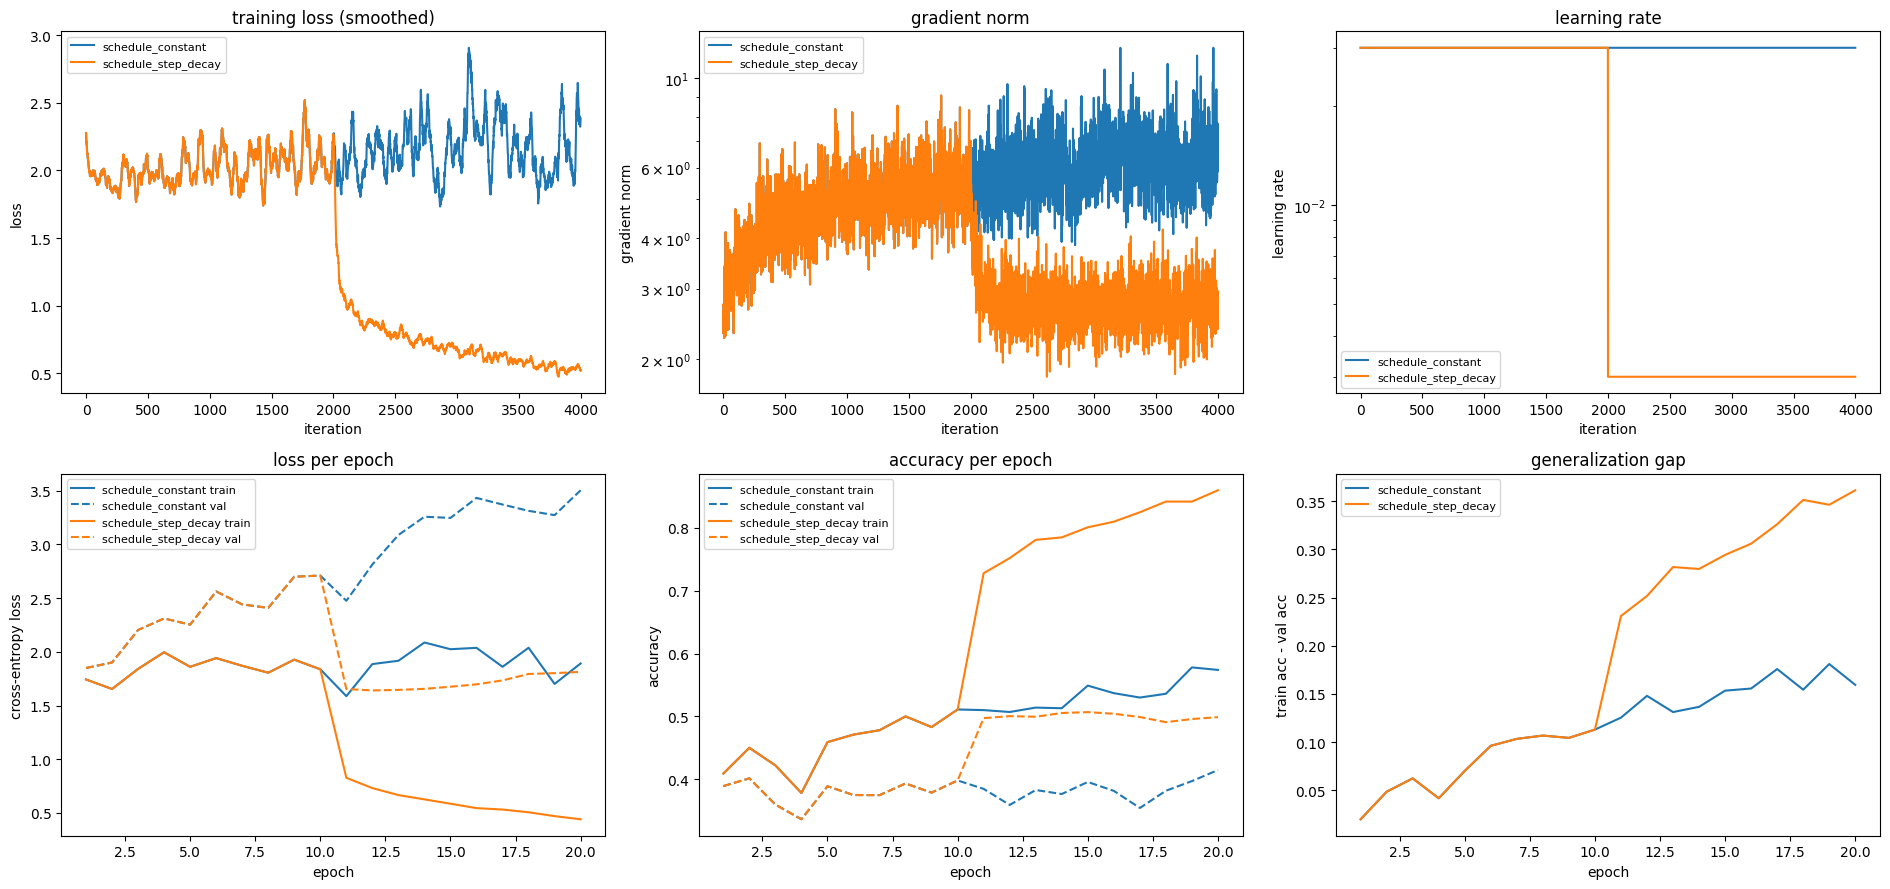

In [18]:
# Provided: the same SGD+Momentum run with a constant and a step-decay learning rate.
def make_schedule_loader():
    return TensorLoader(data['x_train'][:20000], data['y_train'][:20000],
                        batch_size=100, shuffle=True)


schedule_logs = {}
for name, step_size in [('constant', None), ('step_decay', 10)]:
    torch.manual_seed(SEED)
    model = simple_mlp().to(device)
    optimizer = SGDMomentum(model.parameters(), lr=3e-2, momentum=0.9)
    scheduler = StepDecay(optimizer, step_size=step_size, gamma=0.1) if step_size else None
    schedule_logs[name] = train_model(
        model, optimizer, make_schedule_loader(), val_loader, num_epochs=20,
        name=f'schedule_{name}', train_eval_loader=opt_eval_loader,
        scheduler=scheduler, verbose=False)
    epochs = schedule_logs[name].epochs
    print(f"{name:10s}: final train loss {epochs['train_loss'][-1]:.4f}, "
          f"best val acc {max(epochs['val_acc']):.3f}")

plot_logs(list(schedule_logs.values()))
plt.show()


In [19]:
# Provided check: the logged learning rate follows the schedule, and the decay helps.
steps_per_epoch = len(make_schedule_loader())
decay_lrs = schedule_logs['step_decay'].steps['lr']
assert all(abs(lr - 3e-2) < 1e-12 for lr in decay_lrs[:10 * steps_per_epoch])
assert all(abs(lr - 3e-3) < 1e-12 for lr in decay_lrs[10 * steps_per_epoch:])
assert all(abs(lr - 3e-2) < 1e-12 for lr in schedule_logs['constant'].steps['lr'])

constant = schedule_logs['constant'].epochs
decay = schedule_logs['step_decay'].epochs
assert decay['train_loss'][-1] < 0.6 * constant['train_loss'][-1]
assert max(decay['val_acc']) >= max(constant['val_acc']) + 0.03
print('Learning rate schedule check passed')


Learning rate schedule check passed


#### Question 1.7: Reading Optimization Curves [written] (6 points)

---

Answer using the plots from Questions 1.5 and 1.6 (2 points each):

1. Rank the four optimizers by how fast they reduce the training loss. Explain
   the ranking with their update rules.
2. Compare the Adam run with the large learning rate to the well-tuned Adam
   run. Describe how the smoothed loss, gradient-norm, and accuracy curves
   differ, and explain why.
3. Compare the constant and step-decay runs of Question 1.6. Describe what
   happens to the learning-rate, smoothed-loss, and train/validation curves at
   the epoch where the learning rate drops, and explain why a smaller learning
   rate late in training helps.

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 1.7 -->

1. From fastest to slowest (final training loss after 10 epochs): Adam (0.377) < SGD+Momentum (0.559) < RMSProp (0.737) < plain SGD (1.105). Plain SGD only uses the current mini-batch gradient with the same step size for every parameter, so it moves slowly and follows the noise of each batch. Momentum keeps a velocity $v \leftarrow \mu v + g$, so in directions where the gradient keeps the same sign the step builds up to about $\eta/(1-\mu) = 10\eta$, and the zig-zag parts cancel out. RMSProp divides each gradient by the running RMS of its own past gradients, so parameters with small gradients get larger steps; this made it the fastest in the first epochs (1.54 vs 1.67 for momentum), but it has no momentum, so later it was overtaken by momentum. Adam combines both ideas (a momentum average $m$ and the RMS scaling $v$, with bias correction so the first steps are not too small), so it reduced the training loss the fastest.

2. With the well-tuned Adam (lr = 1e-3), the smoothed loss goes down smoothly (about 1.99 in the first epoch to 0.49 in the last), the gradient norm stays around 3 to 6, and the training accuracy rises to 0.90. With lr = 1e-2, the loss starts much higher (about 7.4 in the first epoch), only goes down to about 1.6 at epoch 4, and then goes back up to 4.2 by epoch 10 while jumping around a lot. The gradient norm is much larger (median about 19, up to 64) and keeps growing, the training accuracy stays around 0.5, and the validation accuracy stays around 0.32 while the validation loss rises to 7.6. Adam normalizes each update, so every weight moves by about $\eta$ per step no matter how small its gradient is. With $\eta = 10^{-2}$ that step is about as large as the weights themselves, so the updates overshoot the good region, the loss oscillates and diverges, and the network ends up in places with very large gradients.

3. Until epoch 10 the two runs are exactly the same (same initialization and same batches), so their curves overlap. The constant run stays noisy around a loss of about 2.0 for the whole 20 epochs and does not improve (validation accuracy stays between about 0.34 and 0.41). In the step-decay run the learning-rate panel drops from 3e-2 to 3e-3 after epoch 10, and right after it the smoothed loss falls sharply (about 2.05 in epoch 10, 1.11 in epoch 11, 0.53 in epoch 20) and becomes much less noisy (std 0.29 to 0.07). The training accuracy jumps from 0.51 to 0.73 and the validation accuracy from 0.40 to 0.50 in one epoch, and the validation loss drops from 2.71 to 1.65. After that the training curves keep improving while the validation accuracy stays around 0.50 and the validation loss slowly rises, so the gap starts to grow. A large learning rate is good early because it makes big progress, but near a minimum the steps are too large, so the parameters keep bouncing around the valley instead of going down into it. A smaller learning rate later lets the updates settle into the bottom of the valley and refine the solution.

<!-- ANSWER_END: 1.7 -->

---


## Part 2: Normalization and Generalization (48 points)

A network that reaches a low training loss is not necessarily a good model: it
must also perform well on data it has never seen. In this part you will
implement normalization and regularization layers, study how initialization and
normalization affect deep networks, and use the training logs to diagnose and
reduce overfitting.

**Lecture Connection**

> Training minimizes error on observed examples  
> Low training loss can coexist with poor generalization  
> Generalization is the central goal of supervised learning  
> *(Lec06 Training and Generalization, p. 3)*


### Section 3: Normalization and Regularization Layers


#### Question 2.1: Batch and Layer Normalization [code] (10 points)

Implement batch normalization and layer normalization for fully connected
layers without using `nn.BatchNorm1d` or `nn.LayerNorm`.

**Lecture Connection**

> Batch statistics normalize intermediate activations during training  
> Learnable scale and shift preserve representational flexibility  
> Running statistics are used during inference  
> *(Lec03 Convolutional Neural Networks, p. 26)*

**Concept Connection**

For an input $x \in \mathbb{R}^{N \times D}$, both layers compute

$$
y = \gamma \odot \frac{x - \mu}{\sqrt{\sigma^2 + \epsilon}} + \beta,
$$

but over different axes. **Batch normalization** computes $\mu, \sigma^2$ of
every feature over the mini-batch (shape `(D,)`). Because test-time
predictions must not depend on the other examples in a batch, it also keeps
exponential moving averages of these statistics and uses them in evaluation
mode:

$$
\mu_{\text{run}} \leftarrow (1-m)\,\mu_{\text{run}} + m\,\mu,\qquad
\sigma^2_{\text{run}} \leftarrow (1-m)\,\sigma^2_{\text{run}} + m\,\tfrac{N}{N-1}\sigma^2 .
$$

**Layer normalization** computes $\mu, \sigma^2$ of every example over its
features (shape `(N, 1)`), so it behaves the same in training and evaluation.

**Implementation Guide and Point Breakdown**

The parameters `weight` ($\gamma$) and `bias` ($\beta$) and the running-statistic
buffers are already created.

- **Batch normalization, training mode (3 points):** Use the biased variance
  (`unbiased=False`) to normalize.
- **Running statistics (3 points):** Update the buffers in place inside
  `torch.no_grad()`, using the unbiased variance as in the equation above.
- **Batch normalization, evaluation mode (2 points):** Use the running
  statistics.
- **Layer normalization (2 points):** Normalize over the last dimension with
  `keepdim=True`.

| Tensor | Shape |
|---|---|
| `x`, `out` | `(N, D)` |
| `weight`, `bias`, `running_mean`, `running_var` | `(D,)` |
| batch statistics | `(D,)` |
| layer statistics | `(N, 1)` |

**Expected Check:** Training-mode outputs, running statistics after two
batches, evaluation-mode outputs, and layer-normalization outputs all match
the PyTorch layers with relative error below `1e-7`.


In [20]:
class BatchNorm1d(nn.Module):
    def __init__(self, num_features, eps=1e-5, momentum=0.1):
        super().__init__()
        self.eps = eps
        self.momentum = momentum
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))
        self.register_buffer('running_mean', torch.zeros(num_features))
        self.register_buffer('running_var', torch.ones(num_features))

    def forward(self, x):
        """
        Inputs:
        - x: Tensor of shape (N, D)

        Returns:
        - out: Tensor of shape (N, D)
        """
        if self.training:
            ####################################################################
            # TODO 2.1 (3/10 points): Normalize x with the mean and the biased #
            # variance of the current mini-batch, then apply self.weight and   #
            # self.bias.                                                       #
            ####################################################################
            mean = x.mean(dim=0)
            var = x.var(dim=0, unbiased=False)
            out = self.weight * (x - mean) / torch.sqrt(var + self.eps) + self.bias
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################

            ####################################################################
            # TODO 2.1 (3/10 points): Update self.running_mean and             #
            # self.running_var in place with an exponential moving average     #
            # using self.momentum. As in nn.BatchNorm1d, the running variance  #
            # uses the unbiased batch variance. The update must not be tracked #
            # by autograd.                                                     #
            ####################################################################
            with torch.no_grad():
                n = x.shape[0]
                self.running_mean.mul_(1 - self.momentum).add_(self.momentum * mean)
                self.running_var.mul_(1 - self.momentum).add_(self.momentum * var * n / (n - 1))
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
        else:
            ####################################################################
            # TODO 2.1 (2/10 points): Normalize x with the running statistics, #
            # then apply self.weight and self.bias.                            #
            ####################################################################
            out = (self.weight * (x - self.running_mean) / torch.sqrt(self.running_var + self.eps)
                   + self.bias)
            ####################################################################
            #                         END OF YOUR CODE                         #
            ####################################################################
        return out


class LayerNorm(nn.Module):
    def __init__(self, num_features, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.weight = nn.Parameter(torch.ones(num_features))
        self.bias = nn.Parameter(torch.zeros(num_features))

    def forward(self, x):
        """
        Inputs:
        - x: Tensor of shape (N, D)

        Returns:
        - out: Tensor of shape (N, D)
        """
        ########################################################################
        # TODO 2.1 (2/10 points): Normalize each example over its feature      #
        # dimension with the biased variance, then apply self.weight and       #
        # self.bias.                                                           #
        ########################################################################
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        out = self.weight * (x - mean) / torch.sqrt(var + self.eps) + self.bias
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return out


In [21]:
# Provided check: compare with nn.BatchNorm1d and nn.LayerNorm.
torch.manual_seed(SEED)
N, D = 8, 5
batches = [3 * torch.randn(N, D, dtype=torch.float64) + 2 for _ in range(2)]
gamma = torch.randn(D, dtype=torch.float64)
beta = torch.randn(D, dtype=torch.float64)

bn = BatchNorm1d(D).double()
reference_bn = nn.BatchNorm1d(D).double()
with torch.no_grad():
    for layer in (bn, reference_bn):
        layer.weight.copy_(gamma)
        layer.bias.copy_(beta)

errors = {}
for i, x in enumerate(batches):
    errors[f'train output {i}'] = max_relative_error(bn(x), reference_bn(x))
errors['running_mean'] = max_relative_error(bn.running_mean, reference_bn.running_mean)
errors['running_var'] = max_relative_error(bn.running_var, reference_bn.running_var)
bn.eval()
reference_bn.eval()
x_test = torch.randn(N, D, dtype=torch.float64)
errors['eval output'] = max_relative_error(bn(x_test), reference_bn(x_test))

ln = LayerNorm(D).double()
reference_ln = nn.LayerNorm(D).double()
with torch.no_grad():
    for layer in (ln, reference_ln):
        layer.weight.copy_(gamma)
        layer.bias.copy_(beta)
errors['layer norm output'] = max_relative_error(ln(batches[0]), reference_ln(batches[0]))

for name, error in errors.items():
    print(f'{name} relative error: {error:.2e}')
    assert error < 1e-7, name

bn.train()
bn(batches[0]).square().sum().backward()
assert bn.weight.grad is not None and bn.bias.grad is not None
assert not bn.running_mean.requires_grad and not bn.running_var.requires_grad


train output 0 relative error: 1.29e-15
train output 1 relative error: 1.16e-15
running_mean relative error: 1.65e-16
running_var relative error: 8.95e-17
eval output relative error: 1.01e-14
layer norm output relative error: 2.29e-15


#### Question 2.2: Dropout [code] (6 points)

Implement inverted dropout without using `nn.Dropout` or `F.dropout`.

**Lecture Connection**

> During training: Some hidden activations are randomly set to zero  
> The network cannot depend on the same subset of neurons every time  
> During inference: The full network is used  
> *(Lec02 Feedforward Neural Networks, p. 47)*

**Concept Connection**

If every activation is kept with probability $1-p$, its expected value during
training is $(1-p)\,x$. **Inverted dropout** divides the kept activations by
$1-p$ during training, so the expected activation equals $x$ and the layer can
simply return its input at test time.

**Implementation Guide and Point Breakdown**

- **Training mode (4 points):** Sample a mask with `torch.rand_like(x) >= p`,
  multiply, and scale by `1 / (1 - p)`. Gradients then flow only through the
  kept elements.
- **Evaluation mode and `p = 0` (2 points):** Return `x` unchanged.

| Tensor | Shape |
|---|---|
| `x`, mask, `out` | any shape |

**Expected Check:** In training mode, the fraction of zeros is within `0.01` of
`p`, kept values are scaled by `1 / (1 - p)`, and the gradient equals the
scaled mask. In evaluation mode the layer returns its input.


In [22]:
class Dropout(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        assert 0 <= p < 1
        self.p = p

    def forward(self, x):
        """
        Inputs:
        - x: Tensor of any shape

        Returns:
        - out: Tensor of the same shape as x
        """
        ########################################################################
        # TODO 2.2 (6 points): Implement inverted dropout. In training mode    #
        # with p > 0, zero each element independently with probability self.p  #
        # and scale the kept elements by 1 / (1 - self.p). Otherwise return x  #
        # unchanged.                                                           #
        ########################################################################
        if not self.training or self.p == 0:
            out = x
        else:
            mask = (torch.rand_like(x) >= self.p).to(x.dtype)
            out = x * mask / (1 - self.p)
        ########################################################################
        #                         END OF YOUR CODE                             #
        ########################################################################
        return out


In [23]:
# Provided check: statistics, scaling, gradients, and evaluation mode of Dropout.
torch.manual_seed(SEED)
x = torch.randn(1000, 1000) + 10  # no exact zeros, so zeros come only from the mask
for p in [0.25, 0.5, 0.75]:
    layer = Dropout(p).train()
    out = layer(x)
    kept = out != 0
    zero_fraction = 1 - kept.float().mean().item()
    print(f'p={p}: fraction of zeros {zero_fraction:.4f}, mean ratio {out.mean().item() / x.mean().item():.4f}')
    assert abs(zero_fraction - p) < 0.01
    assert torch.allclose(out[kept], x[kept] / (1 - p))
    assert torch.equal(layer.eval()(x), x)

x = (torch.randn(20, 30) + 10).requires_grad_()
out = Dropout(0.5).train()(x)
out.sum().backward()
assert torch.allclose(x.grad, (out != 0).float() / 0.5)
assert torch.equal(Dropout(0.0).train()(x), x)
print('Dropout check passed')


p=0.25: fraction of zeros 0.2499, mean ratio 1.0002
p=0.5: fraction of zeros 0.5005, mean ratio 0.9991
p=0.75: fraction of zeros 0.7500, mean ratio 1.0000
Dropout check passed


#### Question 2.3: Configurable MLP [code] (4 points)

Write one function that builds every network used in the experiments of
Part 2.

**Lecture Connection**

> Initialization depends on both layer size and activation function  
> *(Lec02 Feedforward Neural Networks, p. 38)*

**Implementation Guide**

Build `nn.Flatten()` followed, for every entry of `hidden_dims`, by
`nn.Linear`, the optional normalization layer (your `BatchNorm1d` for
`norm='batch'`, your `LayerNorm` for `norm='layer'`), `nn.ReLU()`, and your
`Dropout` if `dropout > 0`. Finish with an `nn.Linear` to `num_classes`.

If `weight_scale` is given, initialize every `nn.Linear` weight from a normal
distribution with mean 0 and standard deviation `weight_scale`
(`nn.init.normal_`) and every bias to zero (`nn.init.zeros_`). Otherwise keep
the default PyTorch initialization.

| Stage | Shape |
|---|---|
| images | `(N, 3, 32, 32)` |
| flattened | `(N, 3072)` |
| hidden layer `i` | `(N, hidden_dims[i])` |
| logits | `(N, num_classes)` |

**Expected Check:** The layer types and order match the specification for
several configurations, the output has shape `(N, 10)`, and the weights follow
the requested scale.


In [24]:
def make_mlp(hidden_dims, norm=None, dropout=0.0, weight_scale=None,
             input_dim=3 * 32 * 32, num_classes=10):
    """
    Build Flatten -> [Linear -> (norm) -> ReLU -> (Dropout)] x len(hidden_dims) -> Linear.

    Inputs:
    - hidden_dims: list of hidden layer sizes
    - norm: None, 'batch', or 'layer'
    - dropout: dropout probability after every hidden ReLU (no Dropout layer if 0)
    - weight_scale: standard deviation of the Linear weights, or None for the default

    Returns:
    - model: nn.Sequential
    """
    ############################################################################
    # TODO 2.3 (4 points): Build the network described in the docstring as an  #
    # nn.Sequential and store it in `model`.                                   #
    ############################################################################
    layers = [nn.Flatten()]
    prev_dim = input_dim
    for hidden_dim in hidden_dims:
        layers.append(nn.Linear(prev_dim, hidden_dim))
        if norm == 'batch':
            layers.append(BatchNorm1d(hidden_dim))
        elif norm == 'layer':
            layers.append(LayerNorm(hidden_dim))
        layers.append(nn.ReLU())
        if dropout > 0:
            layers.append(Dropout(dropout))
        prev_dim = hidden_dim
    layers.append(nn.Linear(prev_dim, num_classes))
    model = nn.Sequential(*layers)

    if weight_scale is not None:
        for layer in model:
            if isinstance(layer, nn.Linear):
                nn.init.normal_(layer.weight, mean=0.0, std=weight_scale)
                nn.init.zeros_(layer.bias)
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return model


In [25]:
# Provided check: architecture, output shape, and initialization of make_mlp.
def layer_types(model):
    return [type(layer).__name__ for layer in model]

assert layer_types(make_mlp([64])) == ['Flatten', 'Linear', 'ReLU', 'Linear']
assert layer_types(make_mlp([64, 32], norm='batch', dropout=0.5)) == [
    'Flatten', 'Linear', 'BatchNorm1d', 'ReLU', 'Dropout',
    'Linear', 'BatchNorm1d', 'ReLU', 'Dropout', 'Linear']
assert layer_types(make_mlp([16], norm='layer')) == ['Flatten', 'Linear', 'LayerNorm', 'ReLU', 'Linear']

torch.manual_seed(SEED)
model = make_mlp([256, 128], weight_scale=0.01)
assert model(torch.randn(5, 3, 32, 32)).shape == (5, 10)
first = model[1]
print('weight std:', first.weight.std().item())
assert abs(first.weight.std().item() - 0.01) < 0.0005
assert torch.all(first.bias == 0)
print('make_mlp check passed')


weight std: 0.010011887177824974


make_mlp check passed


### Section 4: Generalization Experiments


#### Provided: Initialization and Batch Normalization Experiment

The cell below trains a six-hidden-layer network on 1,000 training images for
10 epochs with Adam, for several weight initialization scales, with and without
batch normalization. Every run is logged. The plots summarize each run by its
best validation accuracy, its final training loss, and the gradient norm at
the first iteration. You will interpret them in Question 2.4.

**Lecture Connection**

> If weights are too small: Activations may shrink across layers; Information can gradually disappear  
> If weights are too large: Activations may grow rapidly; Computation can become unstable  
> *(Lec02 Feedforward Neural Networks, p. 37)*


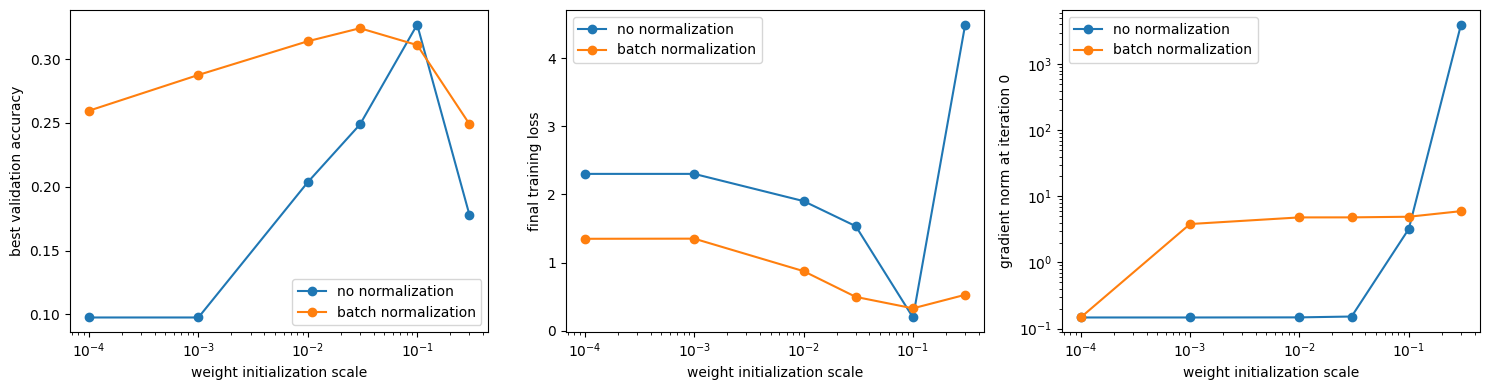

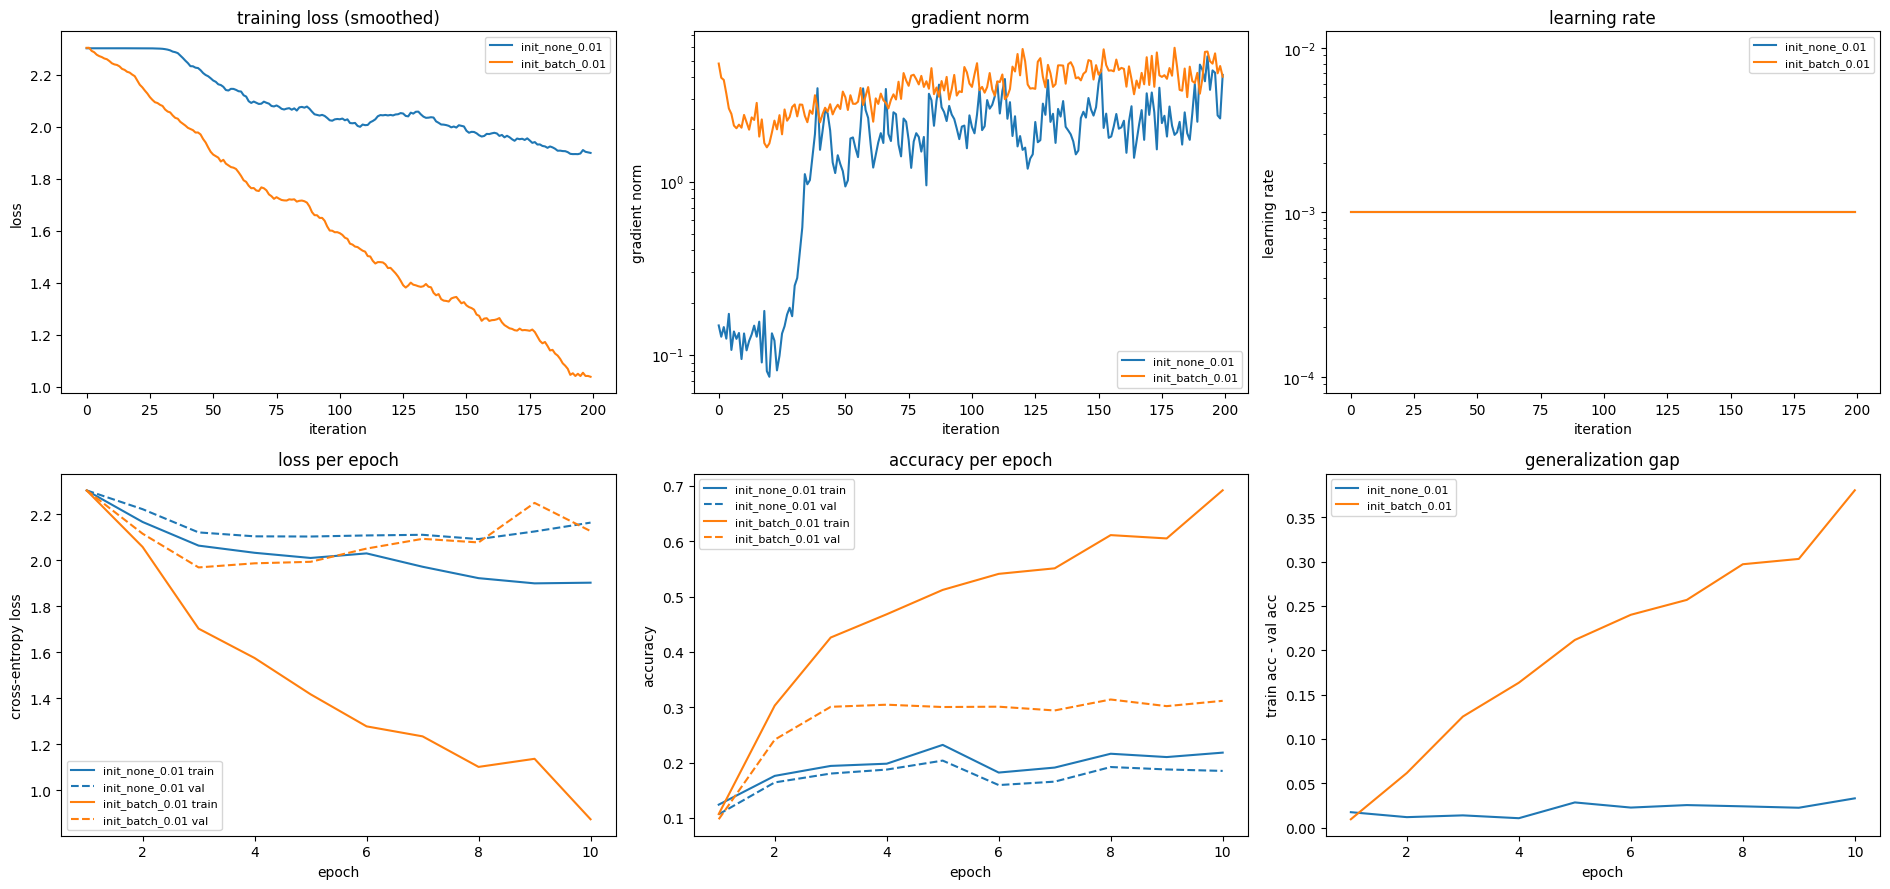

In [26]:
# Provided: weight initialization scale with and without batch normalization.
weight_scales = [1e-4, 1e-3, 1e-2, 3e-2, 1e-1, 3e-1]
init_logs = {}
for norm in [None, 'batch']:
    for scale in weight_scales:
        torch.manual_seed(SEED)
        model = make_mlp([100] * 6, norm=norm, weight_scale=scale).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
        init_loader = TensorLoader(data['x_train'][:1000], data['y_train'][:1000],
                                   batch_size=50, shuffle=True)
        init_logs[norm, scale] = train_model(
            model, optimizer, init_loader, val_loader, num_epochs=10,
            name=f"init_{norm or 'none'}_{scale:g}", verbose=False)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for norm, label in [(None, 'no normalization'), ('batch', 'batch normalization')]:
    logs = [init_logs[norm, scale] for scale in weight_scales]
    axes[0].plot(weight_scales, [max(log.epochs['val_acc']) for log in logs], 'o-', label=label)
    axes[1].plot(weight_scales, [log.epochs['train_loss'][-1] for log in logs], 'o-', label=label)
    axes[2].plot(weight_scales, [log.steps['grad_norm'][0] for log in logs], 'o-', label=label)
for ax, ylabel in zip(axes, ['best validation accuracy', 'final training loss',
                             'gradient norm at iteration 0']):
    ax.set_xscale('log')
    ax.set_xlabel('weight initialization scale')
    ax.set_ylabel(ylabel)
    ax.legend()
axes[2].set_yscale('log')
fig.tight_layout()
plt.show()

plot_logs([init_logs[None, 1e-2], init_logs['batch', 1e-2]])
plt.show()


#### Question 2.4: Normalization and Initialization [written] (6 points)

---

Answer using the plots above (3 points each):

1. For which weight scales does the network without normalization fail to
   train, and what does the gradient-norm plot show for those scales? Explain
   the failure in terms of how activations and gradients change from layer to
   layer, and explain why batch normalization makes training much less
   sensitive to the initialization scale.
2. Batch normalization performs poorly with very small mini-batches, while
   layer normalization does not. Explain why, based on which statistics each
   layer computes.

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.4 -->

1. Without normalization, the network does not learn at all for weight scales 1e-4 and 1e-3: the training loss stays at 2.301 (about $\ln 10$, a uniform guess) and the validation accuracy is 0.098 (chance). It also learns badly for 1e-2 and 3e-2 (best validation accuracy 0.20 and 0.25), and it fails in the other direction at 0.3 (final training loss 4.49). In the gradient-norm plot, the norm at iteration 0 is flat at about 0.15 for every small scale (1e-4 to 3e-2); this is almost only the gradient of the last bias, which means the weights get almost no gradient. At 0.3 the norm is about 4,000, so the gradients explode. Each layer multiplies the activations by $W$, so the scale changes by roughly the same factor at every layer (about $\sigma\sqrt{n/2}$ with ReLU and fan-in $n$). If that factor is smaller than 1, the signal shrinks exponentially over 6 layers, the output becomes almost constant, and the backward pass multiplies by the same small weights, so the gradients vanish too. If it is larger than 1, the activations and gradients grow exponentially and the updates become unstable. Only a scale near 0.1, where the factor is close to 1, trains well. Batch normalization rescales the pre-activations of every layer to zero mean and unit variance over the batch, so multiplying $W$ by a constant does not change the input of the next layer. The signal and the gradients keep the same scale through all 6 layers no matter how $W$ was initialized, so with batch normalization every scale trains (best validation accuracy 0.25 to 0.32, and a gradient norm of about 4 to 6 at iteration 0 for scales from 1e-3 to 0.3).

2. Batch normalization computes the mean and variance of each feature over the examples in the mini-batch. With a very small batch these statistics are estimated from only a few numbers, so they are very noisy, and the output for one example depends on which other examples happen to be in the same batch (with a batch of 1 the variance is 0 and every feature just becomes $\beta$). The running averages built from these noisy statistics also do not match what the network saw during training, so the evaluation behavior is worse. Layer normalization computes the mean and variance of each example over its own features (for example 100 values in a hidden layer), so it does not depend on the batch size at all and behaves the same in training and evaluation.

<!-- ANSWER_END: 2.4 -->

---


#### Question 2.5: Regularization Experiment [code] (10 points)

Train a network that overfits a small training set, and reduce the overfitting
with regularization.

**Lecture Connection**

> Training error becomes very low  
> Validation error stops improving  
> Generalization gap expands over time  
> Limited data can increase memorization  
> *(Lec06 Training and Generalization, p. 35)*

> Stronger regularization can reduce overfitting but may increase underfitting  
> *(Lec06 Training and Generalization, p. 10)*

> Validation performance identifies useful checkpoints  
> Best checkpoint differs from last checkpoint  
> *(Lec06 Training and Generalization, p. 30)*

> Augmentation creates modified views of training samples  
> Appropriate augmentation can improve generalization  
> *(Lec03 Convolutional Neural Networks, p. 34)*

**Concept Connection**

The provided function `run_regularization` trains `make_mlp([512, 512])` on
5,000 training images for 30 epochs with `torch.optim.AdamW`, which applies
weight decay directly to the weights instead of adding an L2 term to the loss.
It accepts a dropout probability, a weight decay, and whether to use
`random_flip_and_crop`. The **generalization gap** is the training accuracy
minus the validation accuracy. **Early stopping** keeps the model from the
epoch with the best validation performance.

**Implementation Guide and Point Breakdown**

- **`best_epoch_summary` (5 points):** From a `TrainingLog`, find the epoch
  with the lowest validation loss (the earliest one if there is a tie), and
  return its epoch number, validation loss, validation accuracy, training
  accuracy, and generalization gap. This is the epoch early stopping would
  select. The validation loss is used because it reacts to overfitting earlier
  and more smoothly than the validation accuracy.
- **Regularization configuration (5 points):** Choose `reg_config`. Start with
  one technique at a time, look at the logged curves, and combine what helps.

**Expected Check:** At its early-stopping epoch, your regularized run reaches a
validation accuracy at least `0.02` higher than the baseline at its
early-stopping epoch, and your final generalization gap is at least `0.1`
smaller than the baseline's.


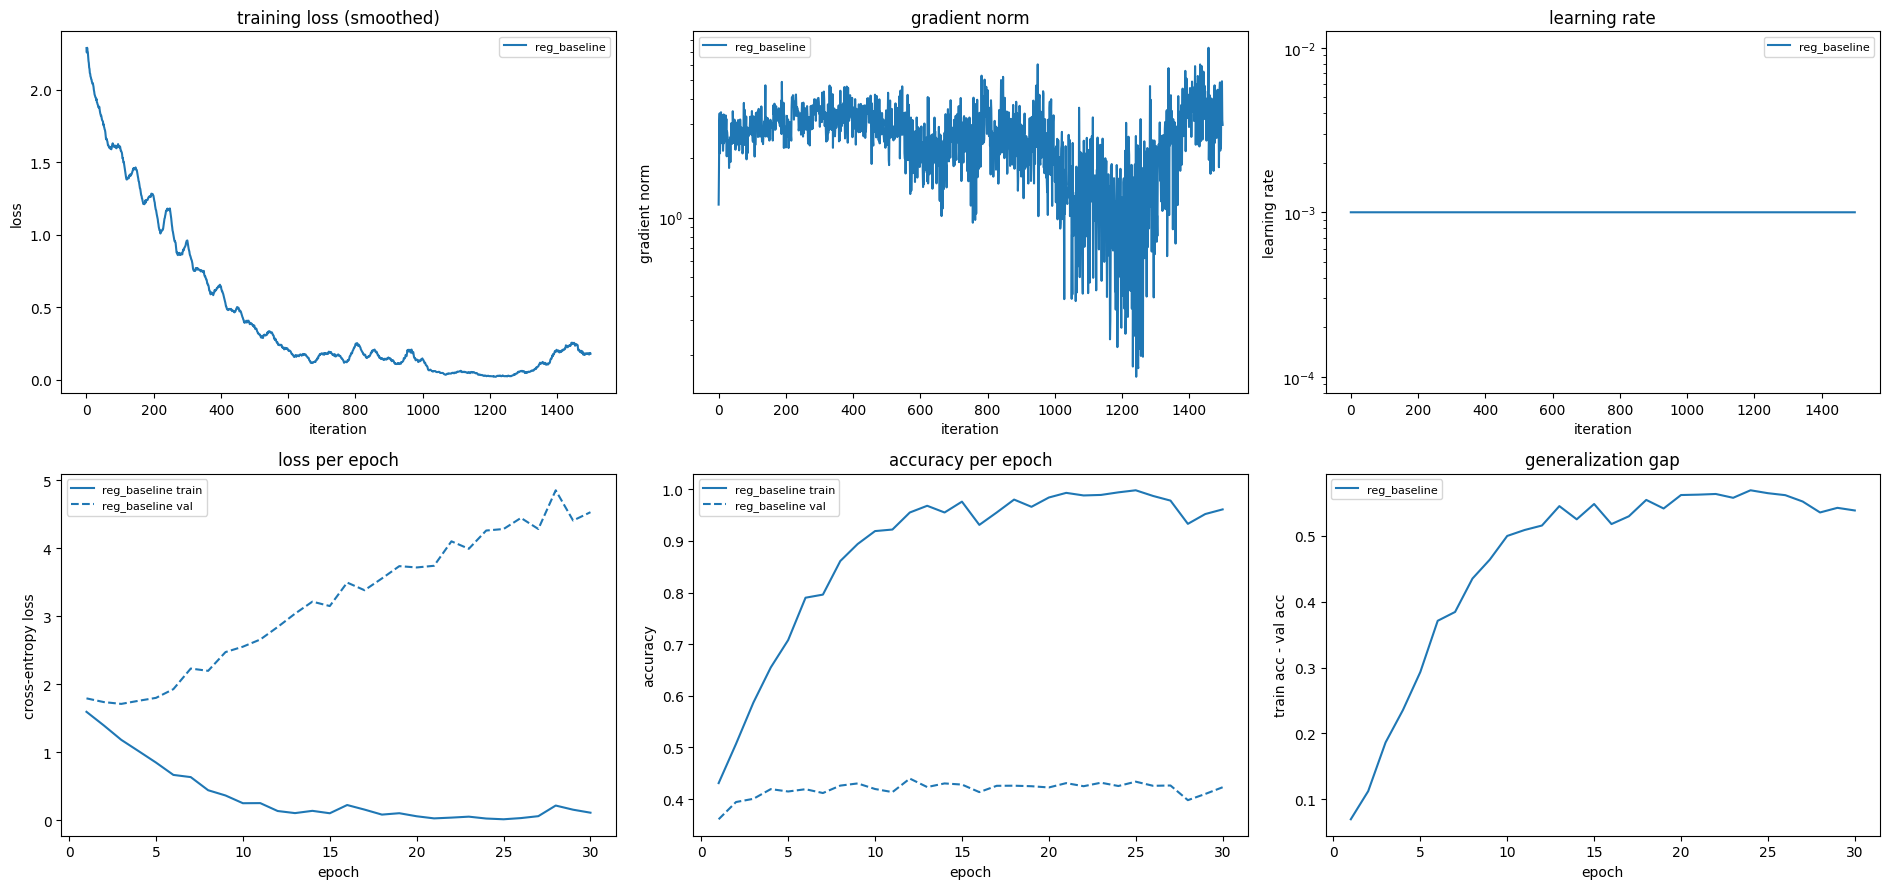

In [27]:
# Provided: the regularization experiment and the unregularized baseline.
reg_x, reg_y = data['x_train'][:5000], data['y_train'][:5000]
reg_eval_loader = TensorLoader(reg_x[:1000], reg_y[:1000], batch_size=500)


def run_regularization(name, dropout=0.0, weight_decay=0.0, augment=False, num_epochs=30):
    torch.manual_seed(SEED)
    model = make_mlp([512, 512], dropout=dropout).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=weight_decay)
    loader = TensorLoader(reg_x, reg_y, batch_size=100, shuffle=True,
                          transform=random_flip_and_crop if augment else None)
    return train_model(model, optimizer, loader, val_loader, num_epochs, name,
                       train_eval_loader=reg_eval_loader, verbose=False)


baseline_log = run_regularization('reg_baseline')
plot_logs([baseline_log])
plt.show()


In [28]:
def best_epoch_summary(log):
    """
    Early stopping in hindsight: select the epoch with the lowest validation loss.

    Inputs:
    - log: TrainingLog with per-epoch 'epoch', 'train_acc', 'val_loss', and 'val_acc'

    Returns a dict with:
    - 'best_epoch': epoch number with the lowest val_loss (the earliest on ties)
    - 'val_loss': val_loss at that epoch
    - 'val_acc': val_acc at that epoch
    - 'train_acc': train_acc at that epoch
    - 'gap': train_acc - val_acc at that epoch
    """
    ############################################################################
    # TODO 2.5 (5/10 points): Return the summary described in the docstring.   #
    ############################################################################
    epochs = log.epochs
    val_losses = epochs['val_loss']
    best = min(range(len(val_losses)), key=lambda i: val_losses[i])  # first index on ties
    summary = {
        'best_epoch': int(epochs['epoch'][best]),
        'val_loss': val_losses[best],
        'val_acc': epochs['val_acc'][best],
        'train_acc': epochs['train_acc'][best],
        'gap': epochs['train_acc'][best] - epochs['val_acc'][best],
    }
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return summary


In [29]:
# Provided check: best_epoch_summary on a hand-made log.
toy_log = TrainingLog('toy')
rows = [(0.5, 1.6, 0.40), (0.7, 1.5, 0.44), (0.9, 1.5, 0.46), (1.0, 1.9, 0.42)]
for epoch, (train_acc, val_loss, val_acc) in enumerate(rows, 1):
    toy_log.log_epoch(epoch=epoch, train_acc=train_acc, val_loss=val_loss, val_acc=val_acc)
summary = best_epoch_summary(toy_log)
print(summary)
assert summary['best_epoch'] == 2
assert abs(summary['val_loss'] - 1.5) < 1e-12
assert abs(summary['val_acc'] - 0.44) < 1e-12
assert abs(summary['train_acc'] - 0.7) < 1e-12
assert abs(summary['gap'] - 0.26) < 1e-12
print('baseline:', best_epoch_summary(baseline_log))


{'best_epoch': 2, 'val_loss': 1.5, 'val_acc': 0.44, 'train_acc': 0.7, 'gap': 0.25999999999999995}
baseline: {'best_epoch': 3, 'val_loss': 1.7104685913085937, 'val_acc': 0.4006, 'train_acc': 0.587, 'gap': 0.18639999999999995}


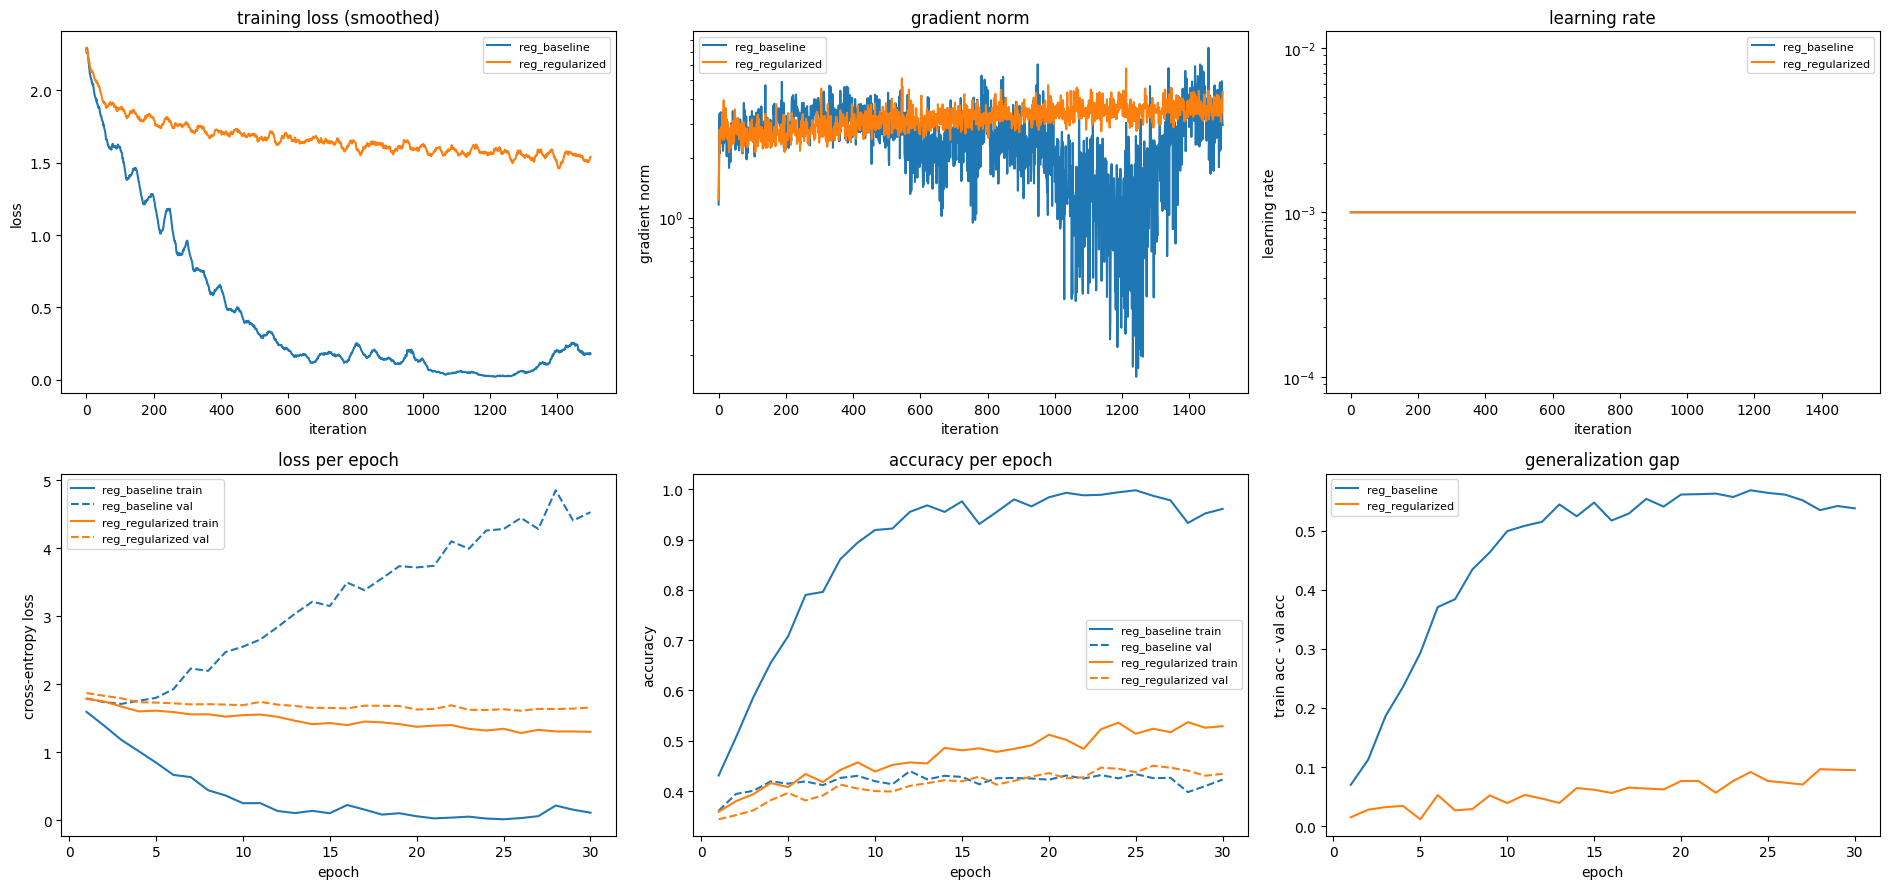

In [30]:
##############################################################################
# TODO 2.5 (5/10 points): Choose a regularization configuration that         #
# improves the validation accuracy at the early-stopping epoch and shrinks   #
# the final generalization gap of the baseline.                              #
##############################################################################
reg_config = {
    'dropout': 0.2,       # dropout probability in [0, 1)
    'weight_decay': 0.1,  # AdamW weight decay
    'augment': True,       # True to use random_flip_and_crop
}
##############################################################################
#                         END OF YOUR CODE                                   #
##############################################################################

regularized_log = run_regularization('reg_regularized', **reg_config)
plot_logs([baseline_log, regularized_log])
plt.show()


In [31]:
# Provided check: the regularized run generalizes better than the baseline.
baseline_summary = best_epoch_summary(baseline_log)
regularized_summary = best_epoch_summary(regularized_log)


def final_gap(log):
    return log.epochs['train_acc'][-1] - log.epochs['val_acc'][-1]


print('baseline   :', baseline_summary, f'final gap {final_gap(baseline_log):.3f}')
print('regularized:', regularized_summary, f'final gap {final_gap(regularized_log):.3f}')
assert regularized_summary['val_acc'] >= baseline_summary['val_acc'] + 0.02
assert final_gap(regularized_log) <= final_gap(baseline_log) - 0.1
print('Regularization check passed')


baseline   : {'best_epoch': 3, 'val_loss': 1.7104685913085937, 'val_acc': 0.4006, 'train_acc': 0.587, 'gap': 0.18639999999999995} final gap 0.538
regularized: {'best_epoch': 26, 'val_loss': 1.609981494140625, 'val_acc': 0.4504, 'train_acc': 0.524, 'gap': 0.0736} final gap 0.095
Regularization check passed


#### Provided: Ablation of Your Configuration

The cell below reruns the experiment with each technique of your configuration
on its own, keeping everything else fixed, so that you can see what each one
contributes. You will use the results in Question 2.7.

**Lecture Connection**

> Begin with a no augmentation baseline  
> Add one transformation while holding other settings fixed  
> *(Lec03 Convolutional Neural Networks, p. 38)*


reg_baseline           early-stopping epoch  3: val loss 1.710, val acc 0.401; final gap 0.538
reg_dropout_only       early-stopping epoch  4: val loss 1.680, val acc 0.423; final gap 0.552
reg_weight_decay_only  early-stopping epoch  3: val loss 1.710, val acc 0.408; final gap 0.542
reg_augment_only       early-stopping epoch 14: val loss 1.638, val acc 0.439; final gap 0.160
reg_regularized        early-stopping epoch 26: val loss 1.610, val acc 0.450; final gap 0.095


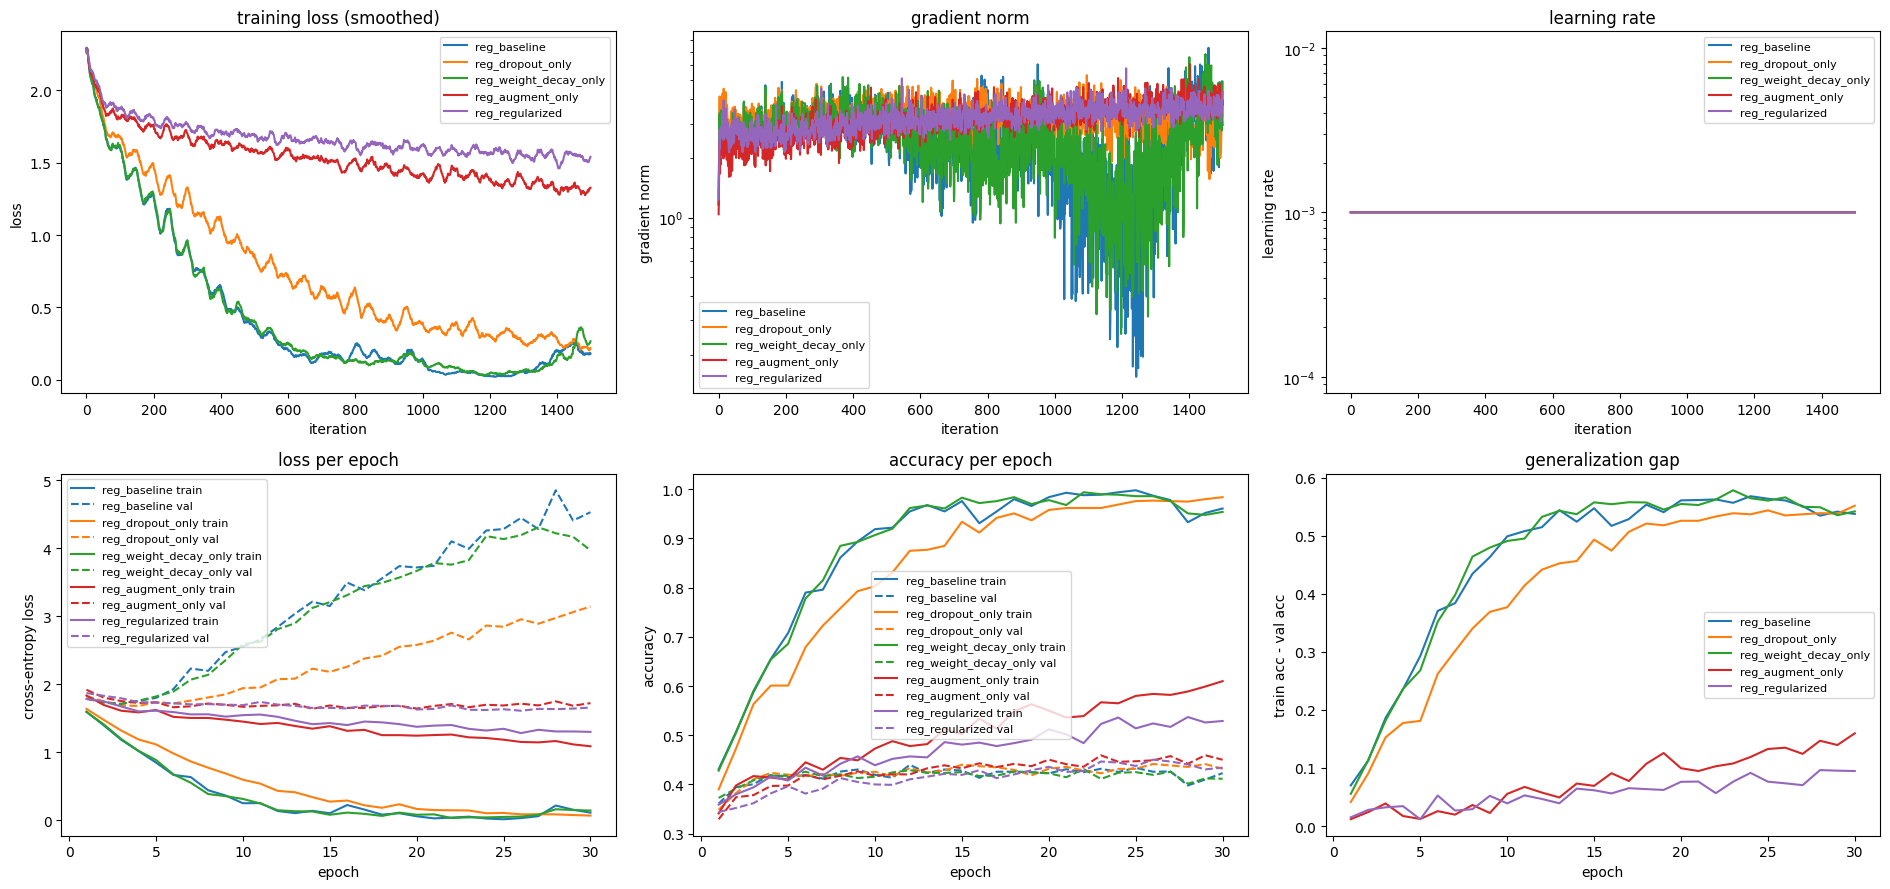

In [32]:
# Provided: one run per technique of reg_config, each on its own.
ablation_logs = [baseline_log]
if reg_config['dropout'] > 0:
    ablation_logs.append(run_regularization('reg_dropout_only', dropout=reg_config['dropout']))
if reg_config['weight_decay'] > 0:
    ablation_logs.append(run_regularization('reg_weight_decay_only', weight_decay=reg_config['weight_decay']))
if reg_config['augment']:
    ablation_logs.append(run_regularization('reg_augment_only', augment=True))
ablation_logs.append(regularized_log)

for log in ablation_logs:
    summary = best_epoch_summary(log)
    print(f"{log.name:22s} early-stopping epoch {summary['best_epoch']:2d}: "
          f"val loss {summary['val_loss']:.3f}, val acc {summary['val_acc']:.3f}; "
          f"final gap {final_gap(log):.3f}")
plot_logs(ablation_logs)
plt.show()


#### Question 2.6: Comparing Runs from Saved Logs [code] (4 points)

Every run of this assignment saved its log to `logs/`. Reload those files and
summarize all runs in one table, so that experiments can be compared after the
fact without retraining anything.

**Lecture Connection**

> Record model and training configurations
> Save best checkpoints and evaluation outputs
> Report enough information to reconstruct the experiment
> *(Lec06 Training and Generalization, p. 37)*

**Implementation Guide**

For every name, load the run with `TrainingLog.load(name, log_dir)` (read it
from disk, not from a variable in memory), find its early-stopping epoch with
`best_epoch_summary`, and append one dictionary with the keys below.

| Key | Value |
|---|---|
| `name` | run name |
| `epochs` | number of logged epochs |
| `best_epoch`, `best_val_loss`, `val_acc_at_best` | early-stopping epoch and its validation loss and accuracy |
| `final_train_acc`, `final_val_acc` | accuracies at the last epoch |
| `final_gap` | `final_train_acc - final_val_acc` |

**Expected Check:** The summary of logs written to a separate directory matches
hand-computed values, and the summary of `reg_baseline` read from disk matches
the in-memory baseline log.


In [33]:
def summarize_saved_logs(names, log_dir='logs'):
    """
    Reload the saved logs of several runs and summarize each run in one row.

    Inputs:
    - names: list of run names; run <name> was saved as <log_dir>/<name>_*.csv
    - log_dir: directory of the saved logs

    Returns:
    - rows: list with one dict per name, in the same order, with the keys
      'name', 'epochs', 'best_epoch', 'best_val_loss', 'val_acc_at_best',
      'final_train_acc', 'final_val_acc', and 'final_gap'
    """
    rows = []
    ############################################################################
    # TODO 2.6 (4 points): For every name, load its log from log_dir with      #
    # TrainingLog.load, find its early-stopping epoch with best_epoch_summary, #
    # and append one dict with the keys described in the docstring.            #
    ############################################################################
    for name in names:
        log = TrainingLog.load(name, log_dir)
        summary = best_epoch_summary(log)
        epochs = log.epochs
        rows.append({
            'name': name,
            'epochs': len(epochs['epoch']),
            'best_epoch': summary['best_epoch'],
            'best_val_loss': summary['val_loss'],
            'val_acc_at_best': summary['val_acc'],
            'final_train_acc': epochs['train_acc'][-1],
            'final_val_acc': epochs['val_acc'][-1],
            'final_gap': epochs['train_acc'][-1] - epochs['val_acc'][-1],
        })
    ############################################################################
    #                         END OF YOUR CODE                                 #
    ############################################################################
    return rows


In [34]:
# Provided check: summarize logs written to a separate directory, then a real run.
check_dir = 'logs_check'
for name, val_losses in [('toy_a', [1.2, 0.9, 1.1]), ('toy_b', [2.0, 1.8, 1.7, 1.75])]:
    toy = TrainingLog(name)
    for epoch, val_loss in enumerate(val_losses, 1):
        toy.log_epoch(epoch=epoch, train_loss=1.0 / epoch, train_acc=0.5 + 0.1 * epoch,
                      val_loss=val_loss, val_acc=0.4 + 0.01 * epoch)
    toy.log_step(step=0, loss=1.0, grad_norm=1.0, lr=0.1)
    toy.save(check_dir)

rows = summarize_saved_logs(['toy_b', 'toy_a'], log_dir=check_dir)
print(rows)
assert [row['name'] for row in rows] == ['toy_b', 'toy_a']
assert rows[0]['epochs'] == 4 and rows[0]['best_epoch'] == 3 and abs(rows[0]['best_val_loss'] - 1.7) < 1e-12
assert abs(rows[0]['val_acc_at_best'] - 0.43) < 1e-12
assert abs(rows[0]['final_train_acc'] - 0.9) < 1e-12 and abs(rows[0]['final_val_acc'] - 0.44) < 1e-12
assert abs(rows[0]['final_gap'] - 0.46) < 1e-12
assert rows[1]['epochs'] == 3 and rows[1]['best_epoch'] == 2

baseline_row = summarize_saved_logs(['reg_baseline'])[0]
expected = best_epoch_summary(baseline_log)
assert baseline_row['best_epoch'] == expected['best_epoch']
assert abs(baseline_row['val_acc_at_best'] - expected['val_acc']) < 1e-9
assert abs(baseline_row['final_gap'] - final_gap(baseline_log)) < 1e-9
print('summarize_saved_logs check passed')


[{'name': 'toy_b', 'epochs': 4, 'best_epoch': 3, 'best_val_loss': 1.7, 'val_acc_at_best': 0.43000000000000005, 'final_train_acc': 0.9, 'final_val_acc': 0.44, 'final_gap': 0.46}, {'name': 'toy_a', 'epochs': 3, 'best_epoch': 2, 'best_val_loss': 0.9, 'val_acc_at_best': 0.42000000000000004, 'final_train_acc': 0.8, 'final_val_acc': 0.43000000000000005, 'final_gap': 0.37}]
summarize_saved_logs check passed


run                          epochs best epoch best val loss val acc @ best final gap
init_batch_0.0001                10          3         2.020          0.225     0.209
init_batch_0.001                 10          5         1.988          0.266     0.223
init_batch_0.01                  10          3         1.968          0.301     0.380
init_batch_0.03                  10          4         1.920          0.309     0.547
init_batch_0.1                   10          4         2.002          0.296     0.653
init_batch_0.3                   10          8         2.452          0.235     0.657
init_none_0.0001                 10          1         2.303          0.098     0.014
init_none_0.001                  10          1         2.303          0.098     0.014
init_none_0.01                   10          8         2.091          0.192     0.033
init_none_0.03                   10          7         2.025          0.224     0.118
init_none_0.1                    10          3        

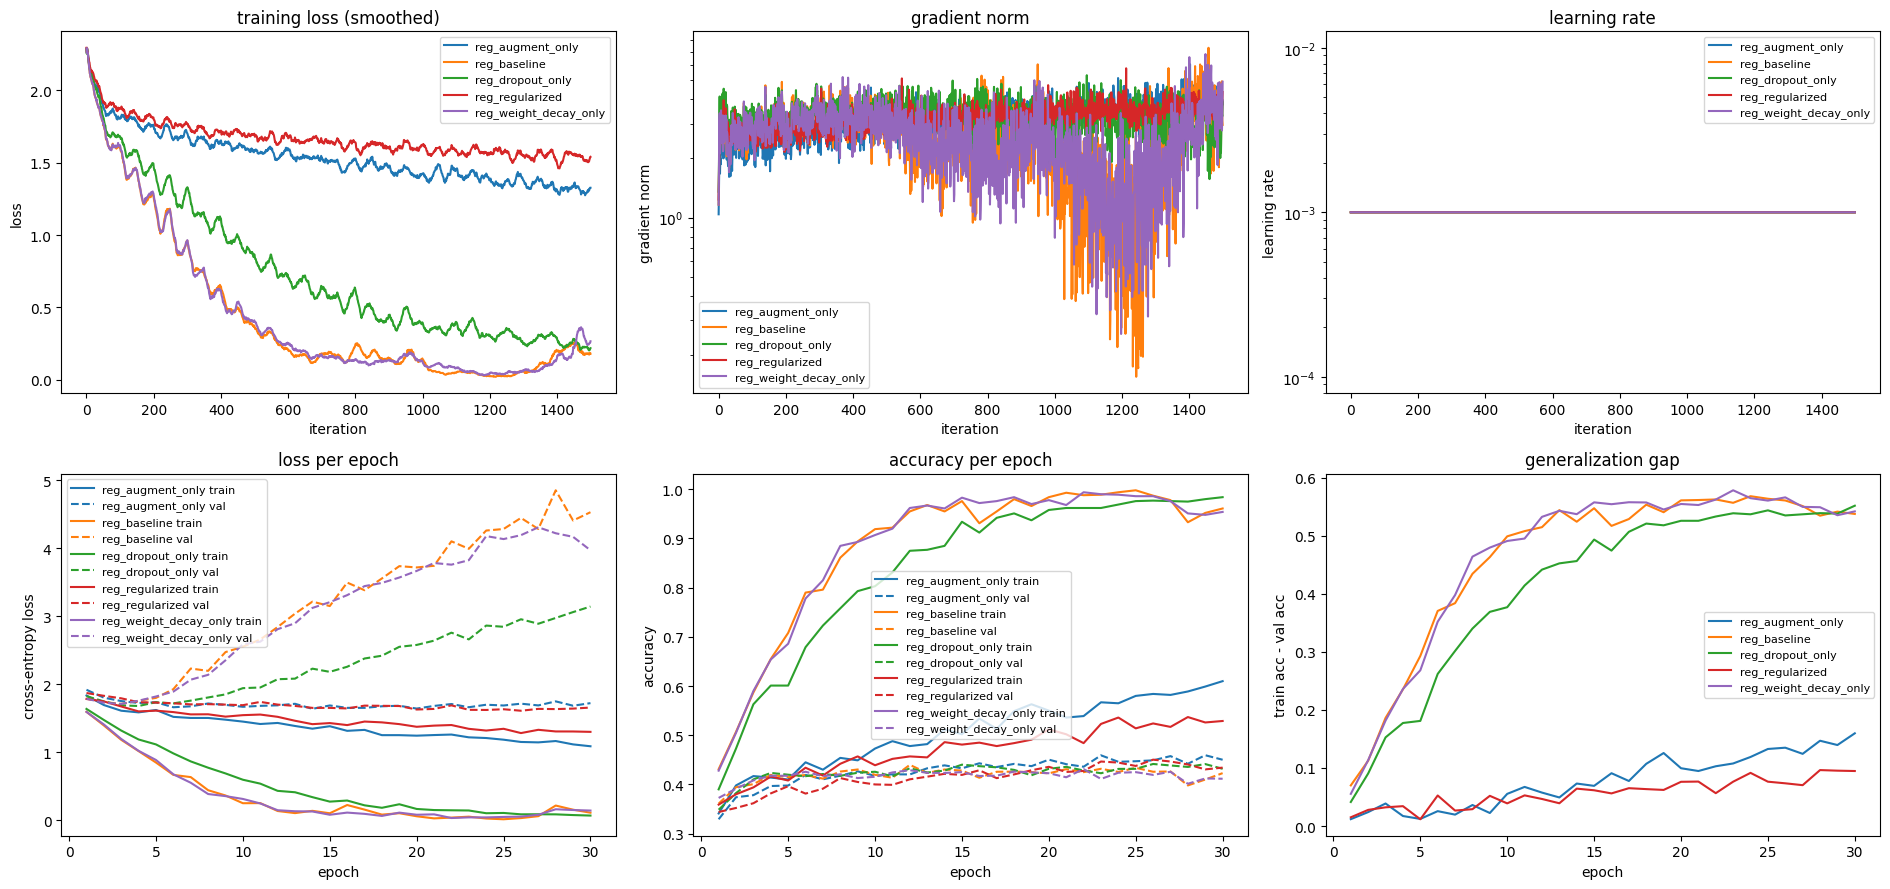

In [35]:
# Provided: summarize every run of this assignment from its saved log files.
run_names = sorted(f[:-len('_epochs.csv')] for f in os.listdir('logs') if f.endswith('_epochs.csv'))
rows = summarize_saved_logs(run_names)

print(f"{'run':28s} {'epochs':>6s} {'best epoch':>10s} {'best val loss':>13s} "
      f"{'val acc @ best':>14s} {'final gap':>9s}")
for row in rows:
    print(f"{row['name']:28s} {row['epochs']:6d} {row['best_epoch']:10d} "
          f"{row['best_val_loss']:13.3f} {row['val_acc_at_best']:14.3f} {row['final_gap']:9.3f}")

# Plot the regularization runs again, this time reloaded from disk.
plot_logs([TrainingLog.load(name) for name in run_names if name.startswith('reg_')])
plt.show()


#### Question 2.7: Diagnosing Training Curves [written] (8 points)

---

Answer using your logged curves from Questions 1.5 and 2.5 and the summary
table of Question 2.6:

1. Diagnose the baseline run, your regularized run, and the Adam run with the
   large learning rate as healthy training, underfitting, overfitting, or
   optimization failure. Support each diagnosis with specific evidence from the
   curves. (4 points)
2. At which epoch would early stopping stop the baseline run, and what would
   early stopping gain and not gain compared with your regularization? (2 points)
3. Based on the ablation, which technique contributed most to your improvement?
   Why is changing one setting at a time necessary to answer this? (2 points)

$\color{blue}{\textit Your Answer:}$

<!-- ANSWER_START: 2.7 -->

1. The baseline is overfitting. Its training accuracy rises to about 0.96 to 1.0 (training loss close to 0.03), but the validation accuracy stops improving around 0.42 to 0.43 after epoch 4. Its validation loss is lowest at epoch 3 (1.710) and then keeps rising up to 4.5, and the generalization gap grows to 0.538 at the end. My regularized run (dropout 0.2, weight decay 0.1, augmentation) looks like healthy training. The training loss (1.78 to 1.30) and the validation loss (1.87 to about 1.61) go down together, the validation accuracy keeps rising to 0.45, and the final gap is only 0.095. It is still slowly improving at epoch 30, so it is not stuck. The Adam run with lr = 1e-2 is an optimization failure. Even the training loss does not go down steadily (1.6 at epoch 4, then back up to 4.2), the iteration loss is very noisy, the gradient norm is 5 to 10 times larger than in the tuned run and keeps growing, and the training accuracy stays around 0.5. This is not overfitting, because the model fails to fit even the training data.

2. Early stopping would stop the baseline at epoch 3, where the validation loss is lowest (1.710, validation accuracy 0.401). It gains a model from before the memorization phase: the validation loss there is 1.71 instead of 4.5 at the end, the gap is 0.19 instead of 0.54, and it costs nothing extra. It does not make the model itself generalize better. It only picks a point on the same training curve, so the validation accuracy at that point stays around 0.40. My regularization changes how the model is trained, so its early-stopping epoch (26) has a better validation accuracy (0.450) and a lower validation loss (1.610) than the baseline at its early-stopping epoch.

3. Data augmentation contributed the most. On its own it raised the validation accuracy at the early-stopping epoch from 0.401 to 0.439, lowered the best validation loss from 1.710 to 1.638, and cut the final gap from 0.538 to 0.160. Dropout alone gave 0.423 with almost no change in the final gap (0.552), and weight decay alone gave 0.408 (gap 0.542). Combining all three was the best (0.450, gap 0.095). Changing one setting at a time is necessary because when several settings change together you only see their combined effect, so you cannot tell which one caused the improvement, or whether one helped while another hurt. Keeping everything else fixed makes each difference come from that one technique only.

<!-- ANSWER_END: 2.7 -->

---


## Submission Checklist

- Fill in the student ID and name.
- Complete every numbered TODO and all three written questions.
- Do not use `torch.optim.SGD` with momentum, `torch.optim.RMSprop`, `torch.optim.Adam`, `torch.optim.lr_scheduler`, `nn.BatchNorm1d`, `nn.LayerNorm`, `nn.Dropout`, or `F.dropout` in submitted implementations.
- Confirm that all provided checks pass.
- Confirm that the `logs/` directory contains the CSV logs of your runs.
- Make sure every plot is visible in the submitted notebook.
- Restart the runtime and run every cell from top to bottom before submission.
